# Training statistics: baseline versus double LR

Run cells in order with the project environment (`pip install -e '.[analysis]'`).
Reads existing logs only; no model loading, training or evaluation.
Change `run_names` below to compare another matched pair.

In [1]:
from pathlib import Path
import csv
import json
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

root = Path.cwd()
if not (root / "artifacts").is_dir():
    root = root.parent
assert (root / "artifacts/pretraining").is_dir(), "Start in the repo root or notebooks/"
run_names = ["gpt-mlx-basic-diagnostics-01", "gpt-mlx-basic-diagnostics-lr2x-01"]
labels = ["Baseline LR", "Double LR"]
colors = ["#2563eb", "#ea580c"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.18, "font.size": 10})

runs = []
for name, label, color in zip(run_names, labels, colors):
    path = root / "artifacts/pretraining" / name
    metadata = json.loads((path / "metadata.json").read_text())
    stats = [json.loads(line) for line in (path / "statistics.jsonl").read_text().splitlines()]
    with (path / "metrics.csv").open() as file:
        metrics = [{key: float(value) if value else np.nan for key, value in row.items()}
                   for row in csv.DictReader(file)]
    assert metadata["status"] == "completed", name
    assert all(row["schema_version"] in (1, 2) for row in stats)
    assert all(a["step"] < b["step"] for a, b in zip(stats, stats[1:]))
    assert sum(row["interval"]["updates"] for row in stats) == metadata["training_config"]["steps"]
    runs.append(dict(name=name, label=label, color=color, path=path,
                     metadata=metadata, stats=stats, metrics=metrics))

a, b = runs
for field in ("model_config", "data_config", "tokenizer_sha256", "statistics_config", "token_cache"):
    assert a["metadata"][field] == b["metadata"][field], field
ta, tb = [r["metadata"]["training_config"] for r in runs]
different = {key for key in ta if ta[key] != tb[key]}
assert different == {"learning_rate", "min_learning_rate"}, different
assert tb["learning_rate"] == 2 * ta["learning_rate"]
assert tb["min_learning_rate"] == 2 * ta["min_learning_rate"]
assert a["stats"][0]["tensors"] == b["stats"][0]["tensors"]
assert a["stats"][0]["probes"] == b["stats"][0]["probes"]
assert [r["step"] for r in a["stats"]] == [r["step"] for r in b["stats"]]
assert [r["step"] for r in a["metrics"]] == [r["step"] for r in b["metrics"]]
print("Matched model, corpus/cache, tokenizer, seed, sampling, budget and measured initialization.")
print("Only training-config differences:", sorted(different))

def values(rows, *keys):
    result = []
    for row in rows:
        for key in keys:
            row = row[key]
        result.append(np.nan if row is None else row)
    return np.asarray(result, dtype=float)

def steps(rows):
    return values(rows, "step") / 1000

def finish(ax, title, ylabel):
    ax.set(title=title, xlabel="Optimizer updates (thousands)", ylabel=ylabel)

def mean_val(run, lo, hi):
    return np.mean([r["val_loss"] for r in run["metrics"] if lo < r["step"] <= hi])

Matched model, corpus/cache, tokenizer, seed, sampling, budget and measured initialization.
Only training-config differences: ['learning_rate', 'min_learning_rate']


**Observed comparison.** The doubled schedule helps early, loses that advantage in the middle,
and finishes close to baseline. Ordinary validation uses ten fixed batches; statistics probes
use two different fixed batches per split. Compare runs within each measurement, not their absolute levels.

Run              Final val   Best val  Best step   Last 10k       PPL
Baseline LR        4.49021    4.44174     185500    4.47358     89.14
Double LR          4.49723    4.43942     185500    4.48412     89.77
PPL = exp(final token cross-entropy); comparable here because tokenizer/data match.


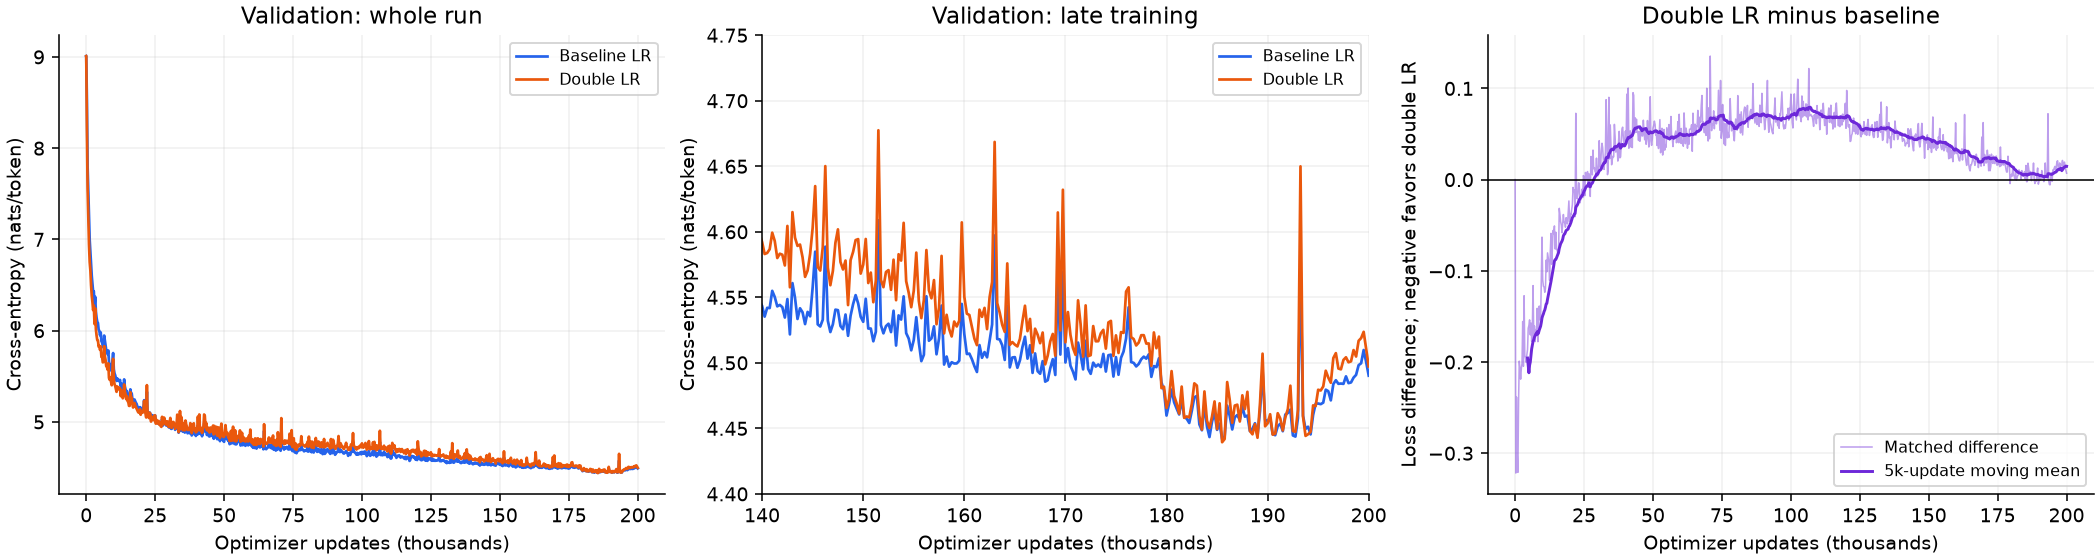

In [2]:
print(f"{'Run':<15} {'Final val':>10} {'Best val':>10} {'Best step':>10} {'Last 10k':>10} {'PPL':>9}")
for run in runs:
    metrics = run["metrics"]
    best = min(metrics, key=lambda row: row["val_loss"])
    final = metrics[-1]["val_loss"]
    print(f"{run['label']:<15} {final:10.5f} {best['val_loss']:10.5f} {int(best['step']):10d} "
          f"{mean_val(run, 190000, 200000):10.5f} {math.exp(final):9.2f}")
print("PPL = exp(final token cross-entropy); comparable here because tokenizer/data match.")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for run in runs:
    x, y = steps(run["metrics"]), values(run["metrics"], "val_loss")
    for ax in axes[:2]:
        ax.plot(x, y, color=run["color"], label=run["label"], linewidth=1.4)
axes[1].set(xlim=(140, 200), ylim=(4.4, 4.75))
delta = values(b["metrics"], "val_loss") - values(a["metrics"], "val_loss")
axes[2].plot(steps(a["metrics"]), delta, color="#6d28d9", alpha=0.45, linewidth=0.8, label="Matched difference")
window = 20  # 5,000 updates; descriptive smoothing, not independent repeats.
axes[2].plot(steps(a["metrics"])[window - 1:], np.convolve(delta, np.ones(window)/window, mode="valid"),
             color="#6d28d9", label="5k-update moving mean")
axes[2].axhline(0, color="black", linewidth=0.8)
finish(axes[0], "Validation: whole run", "Cross-entropy (nats/token)")
finish(axes[1], "Validation: late training", "Cross-entropy (nats/token)")
finish(axes[2], "Double LR minus baseline", "Loss difference; negative favors double LR")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

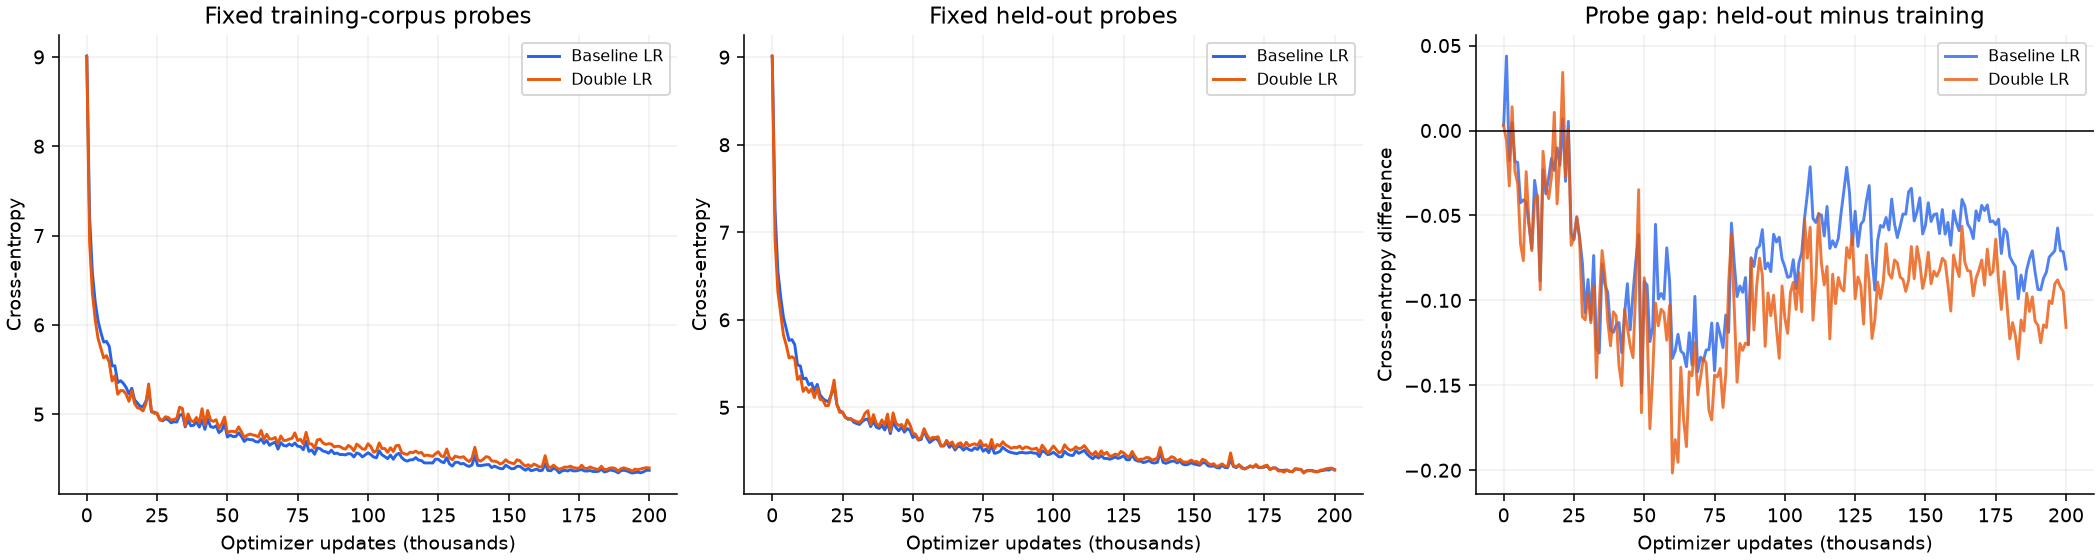

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for run in runs:
    rows = run["stats"]
    train_loss = values(rows, "probes", "train_loss")
    val_loss = values(rows, "probes", "validation_loss")
    axes[0].plot(steps(rows), train_loss, color=run["color"], label=run["label"])
    axes[1].plot(steps(rows), val_loss, color=run["color"], label=run["label"])
    axes[2].plot(steps(rows), val_loss - train_loss, color=run["color"], label=run["label"], alpha=0.8)
finish(axes[0], "Fixed training-corpus probes", "Cross-entropy")
finish(axes[1], "Fixed held-out probes", "Cross-entropy")
finish(axes[2], "Probe gap: held-out minus training", "Cross-entropy difference")
axes[2].axhline(0, color="black", linewidth=0.8)
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

Both probe losses fall without a widening positive gap. This does not establish a capacity
limit: training-corpus probes are not necessarily already seen at each point in a sequential pass,
and the two probe sets can differ in difficulty.

**Clipping is nearly continuous.** Norm means/maxima and clipping fractions below summarize every
update in each interval. Per-tensor measurements later in the notebook are sampled updates only.

Baseline LR: 200,000 updates; clipped 99.4165%
Double LR: 200,000 updates; clipped 99.3600%


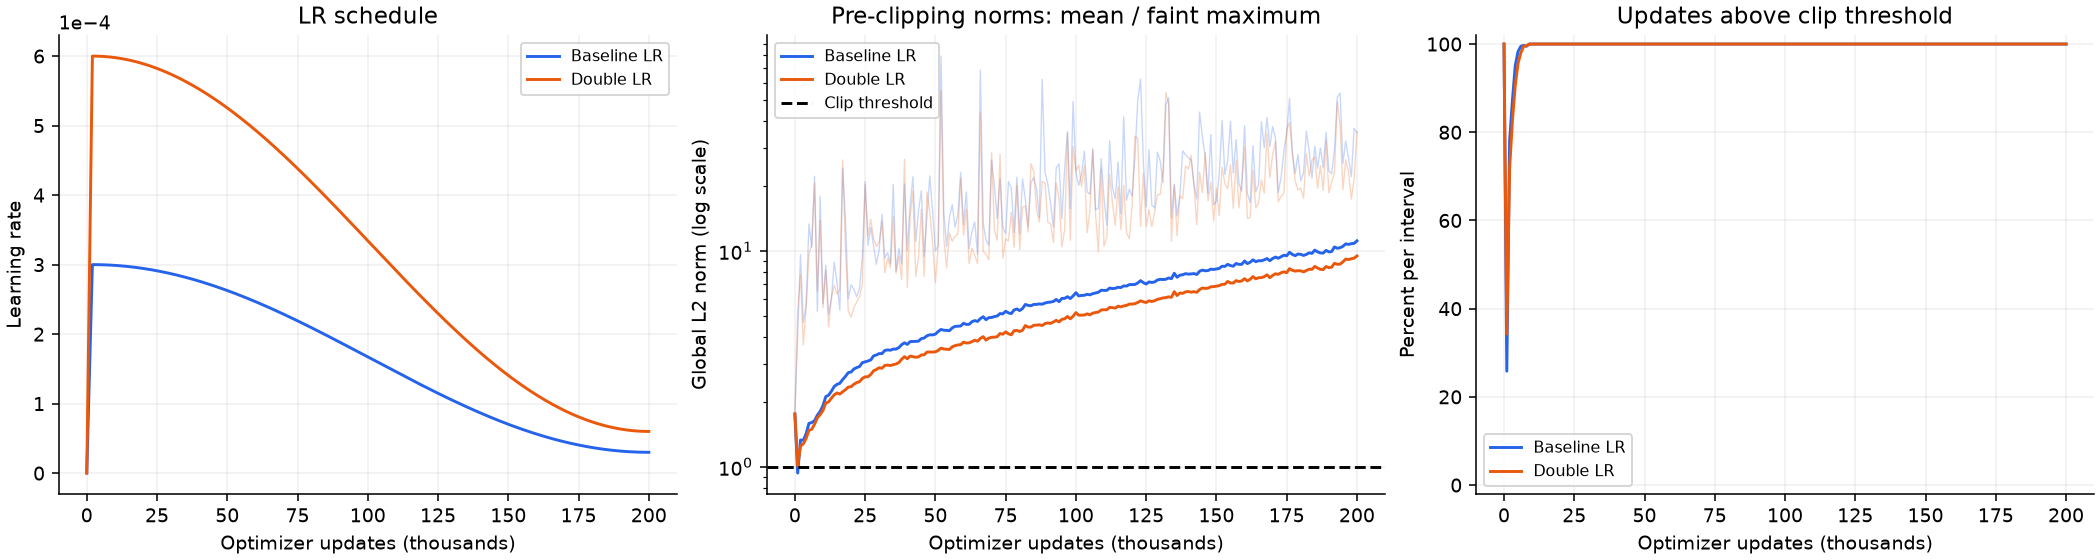

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for run in runs:
    rows = run["stats"][1:]
    axes[0].plot(steps(rows), values(rows, "learning_rate"), color=run["color"], label=run["label"])
    axes[1].plot(steps(rows), values(rows, "interval", "gradient_norm_mean"), color=run["color"], label=run["label"])
    axes[1].plot(steps(rows), values(rows, "interval", "gradient_norm_max"), color=run["color"], alpha=0.25, linewidth=0.7)
    axes[2].plot(steps(rows), 100 * values(rows, "interval", "clipped_fraction"), color=run["color"], label=run["label"])
    count = sum(row["interval"]["updates"] for row in rows)
    clipped = sum(row["interval"]["updates"] * row["interval"]["clipped_fraction"] for row in rows)
    print(f"{run['label']}: {count:,} updates; clipped {100*clipped/count:.4f}%")
axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
axes[1].set_yscale("log")
axes[1].axhline(ta["grad_clip"], color="black", linestyle="--", label="Clip threshold")
axes[2].set_ylim(-2, 102)
finish(axes[0], "LR schedule", "Learning rate")
finish(axes[1], "Pre-clipping norms: mean / faint maximum", "Global L2 norm (log scale)")
finish(axes[2], "Updates above clip threshold", "Percent per interval")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

Frequent clipping means the raw gradient magnitude is usually normalized before AdamW.
It does **not** mean weights barely move: Adam's moments and LR determine the actual update.
Nor does it establish that clipping hurts this model. A matched threshold experiment can test that.

**Layer activity.** Combine tensor RMS using element counts:
`group_rms = sqrt(sum(elements * tensor_rms**2) / sum(elements))`.
Relative update is aggregated update RMS / aggregated preupdate weight RMS, not a mean of tensor ratios.

Final block update RMS (all tensors, element-weighted):
Baseline LR {'blocks.0': '7.18e-06', 'blocks.1': '7.25e-06', 'blocks.2': '7.21e-06', 'blocks.3': '7.24e-06'}
Double LR {'blocks.0': '1.4e-05', 'blocks.1': '1.4e-05', 'blocks.2': '1.42e-05', 'blocks.3': '1.41e-05'}


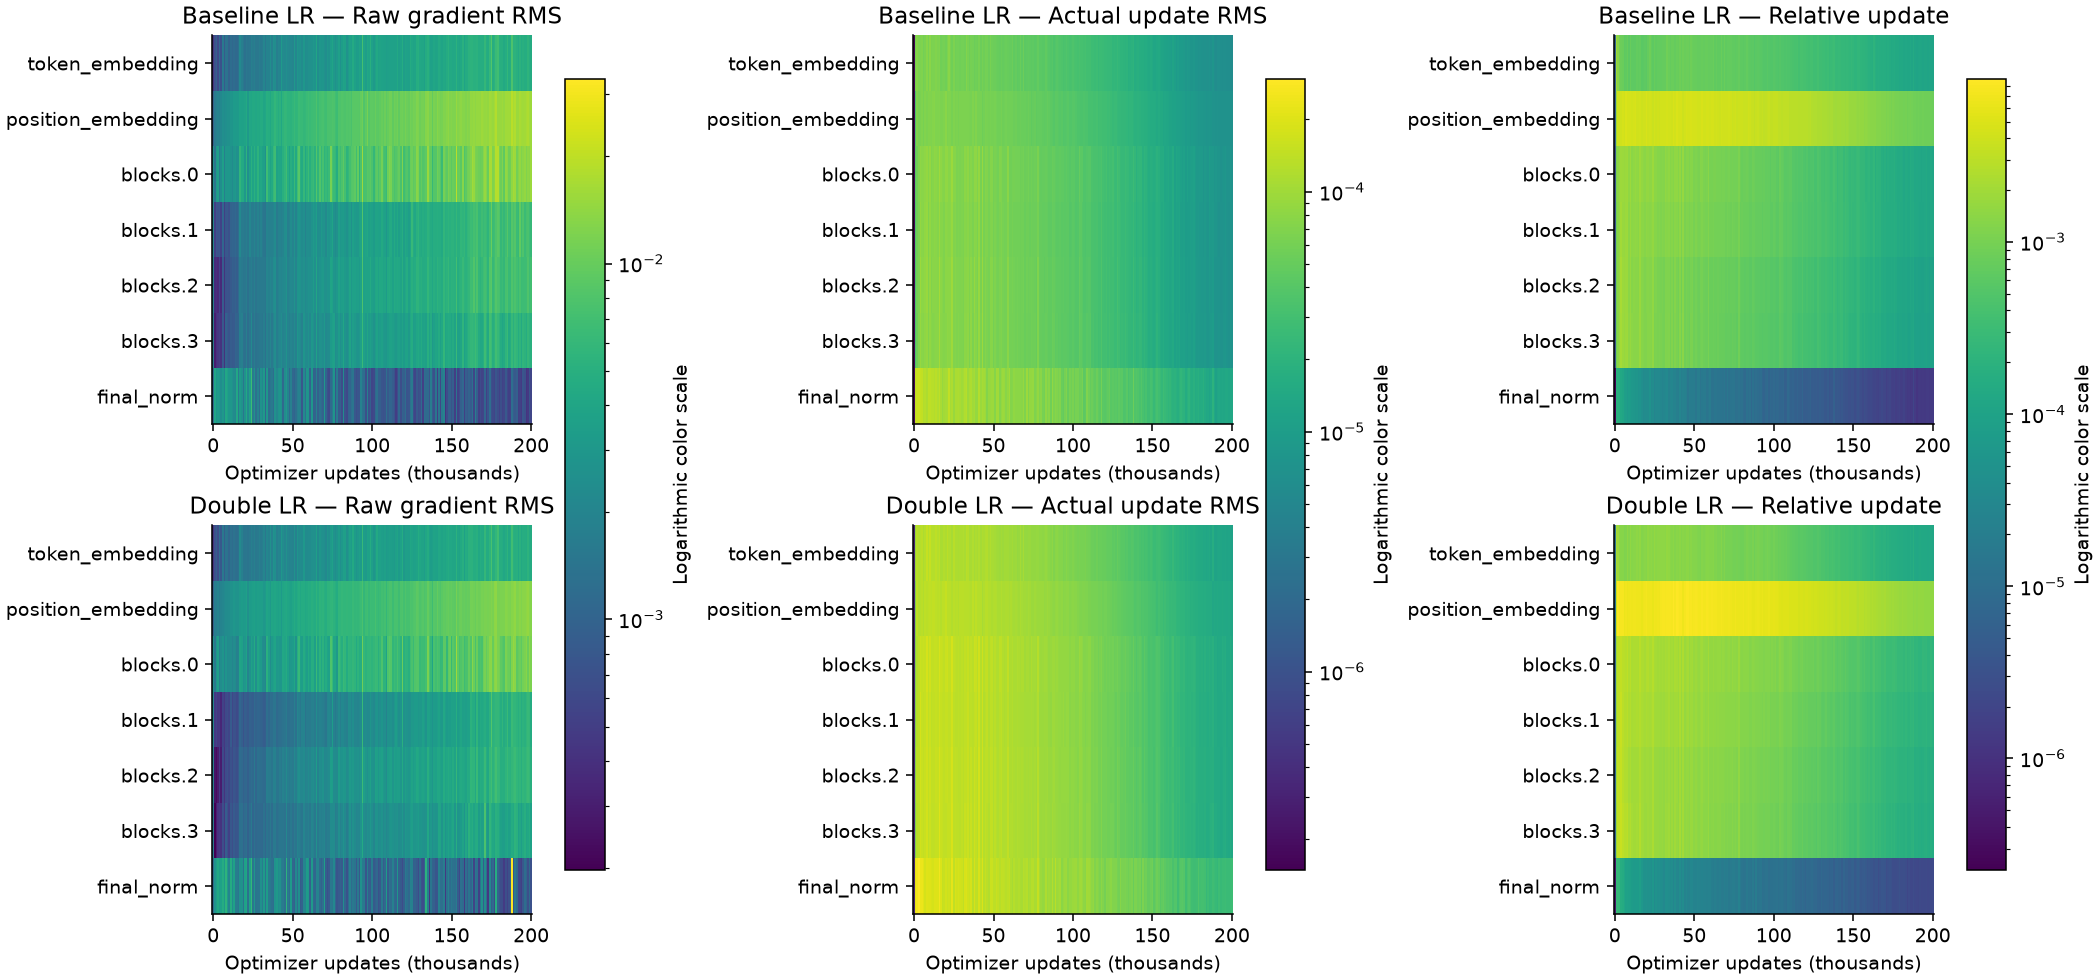

In [5]:
groups = ["token_embedding", "position_embedding"] + [f"blocks.{i}" for i in range(ta.get("n_layers", a["metadata"]["model_config"]["n_layers"]))] + ["final_norm"]

def group_rms(row, group, field):
    tensors = [v for name, v in row["tensors"].items() if name.startswith(group + ".")]
    return math.sqrt(sum(v["elements"] * v[field]**2 for v in tensors) / sum(v["elements"] for v in tensors))

heatmaps = []
for run in runs:
    rows = run["stats"][1:]
    gradient = np.array([[group_rms(row, g, "gradient_rms") for row in rows] for g in groups])
    update = np.array([[group_rms(row, g, "update_rms") for row in rows] for g in groups])
    weights = np.array([[group_rms(row, g, "weight_rms") for row in rows] for g in groups])
    heatmaps.append([gradient, update, update / weights])

fig, axes = plt.subplots(2, 3, figsize=(15, 7), constrained_layout=True)
titles = ["Raw gradient RMS", "Actual update RMS", "Relative update"]
for col, title in enumerate(titles):
    all_values = np.concatenate([h[col].ravel() for h in heatmaps])
    norm = LogNorm(vmin=float(all_values.min()), vmax=float(all_values.max()))
    for index, run in enumerate(runs):
        ax = axes[index, col]
        rows = run["stats"][1:]
        # pcolormesh preserves the nonuniform gap between step1 and step1000.
        mesh = ax.pcolormesh(steps(rows), np.arange(len(groups)), heatmaps[index][col],
                             shading="nearest", cmap="viridis", norm=norm)
        ax.set_yticks(np.arange(len(groups)), groups)
        ax.invert_yaxis()
        ax.set(title=f"{run['label']} — {title}", xlabel="Optimizer updates (thousands)")
        ax.grid(False)
    fig.colorbar(mesh, ax=axes[:, col], shrink=0.9, label="Logarithmic color scale")
plt.show()

print("Final block update RMS (all tensors, element-weighted):")
for run in runs:
    print(run["label"], {g: f"{group_rms(run['stats'][-1], g, 'update_rms'):.3g}"
                          for g in groups if g.startswith("blocks.")})

All four blocks have nonzero sampled gradients and updates. At the final step, block update
RMS is about `7.2e-6` versus `1.4e-5`. There is no observed block-wide disappearance of weight gradients;
this is not a measurement of backward activation gradients or gradient-direction quality.

**Which tensors dominate the raw gradient norm?** Each share is
`elements * gradient_rms**2 / sum(elements * gradient_rms**2)`.
The first attention projection bias has only 128 elements but a substantial share.

Baseline LR: late mean share token_embedding.weight: 29.5%
Baseline LR: late mean share blocks.0.attention.proj.bias: 26.6%
Baseline LR: late mean share position_embedding.weight: 8.6%
Double LR: late mean share token_embedding.weight: 38.0%
Double LR: late mean share blocks.0.attention.proj.bias: 26.0%
Double LR: late mean share position_embedding.weight: 7.3%


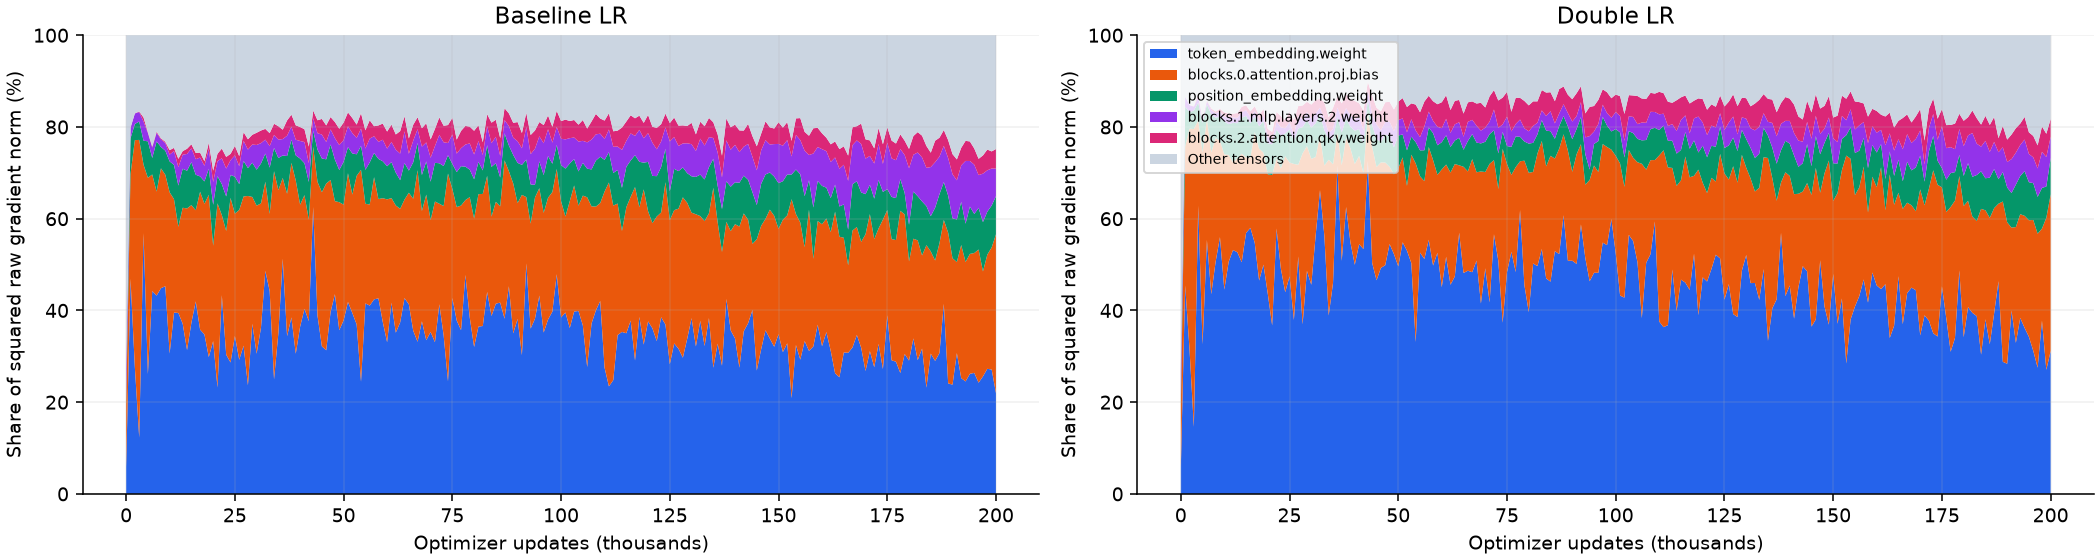

In [6]:
def gradient_shares(row):
    energy = {name: v["elements"] * v["gradient_rms"]**2 for name, v in row["tensors"].items()}
    total = sum(energy.values())
    return {name: value / total for name, value in energy.items()}

names = list(a["stats"][-1]["tensors"])
late_shares = [[gradient_shares(row) for row in run["stats"] if row["step"] > 150000] for run in runs]
top = sorted(names, key=lambda name: np.mean([s[name] for shares in late_shares for s in shares]), reverse=True)[:5]
palette = ["#2563eb", "#ea580c", "#059669", "#9333ea", "#db2777", "#cbd5e1"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True)
for ax, run, late in zip(axes, runs, late_shares):
    rows = run["stats"][1:]
    shares = [gradient_shares(row) for row in rows]
    y = np.array([[s[name] for s in shares] for name in top])
    y = np.vstack([y, 1 - y.sum(axis=0)])
    ax.stackplot(steps(rows), 100*y, labels=top + ["Other tensors"], colors=palette, linewidth=0)
    ax.set_ylim(0, 100)
    finish(ax, run["label"], "Share of squared raw gradient norm (%)")
    for name in top[:3]:
        print(f"{run['label']}: late mean share {name}: {100*np.mean([s[name] for s in late]):.1f}%")
axes[1].legend(loc="upper left", fontsize=7)
plt.show()

**Parameter scales drift.** Final LayerNorm scales grow from RMS 1 to about 14–16.
Token-embedding scales also grow, especially with double LR. These are measured scale changes;
whether they amplify logits or backward signals needs activation/logit probes to establish.

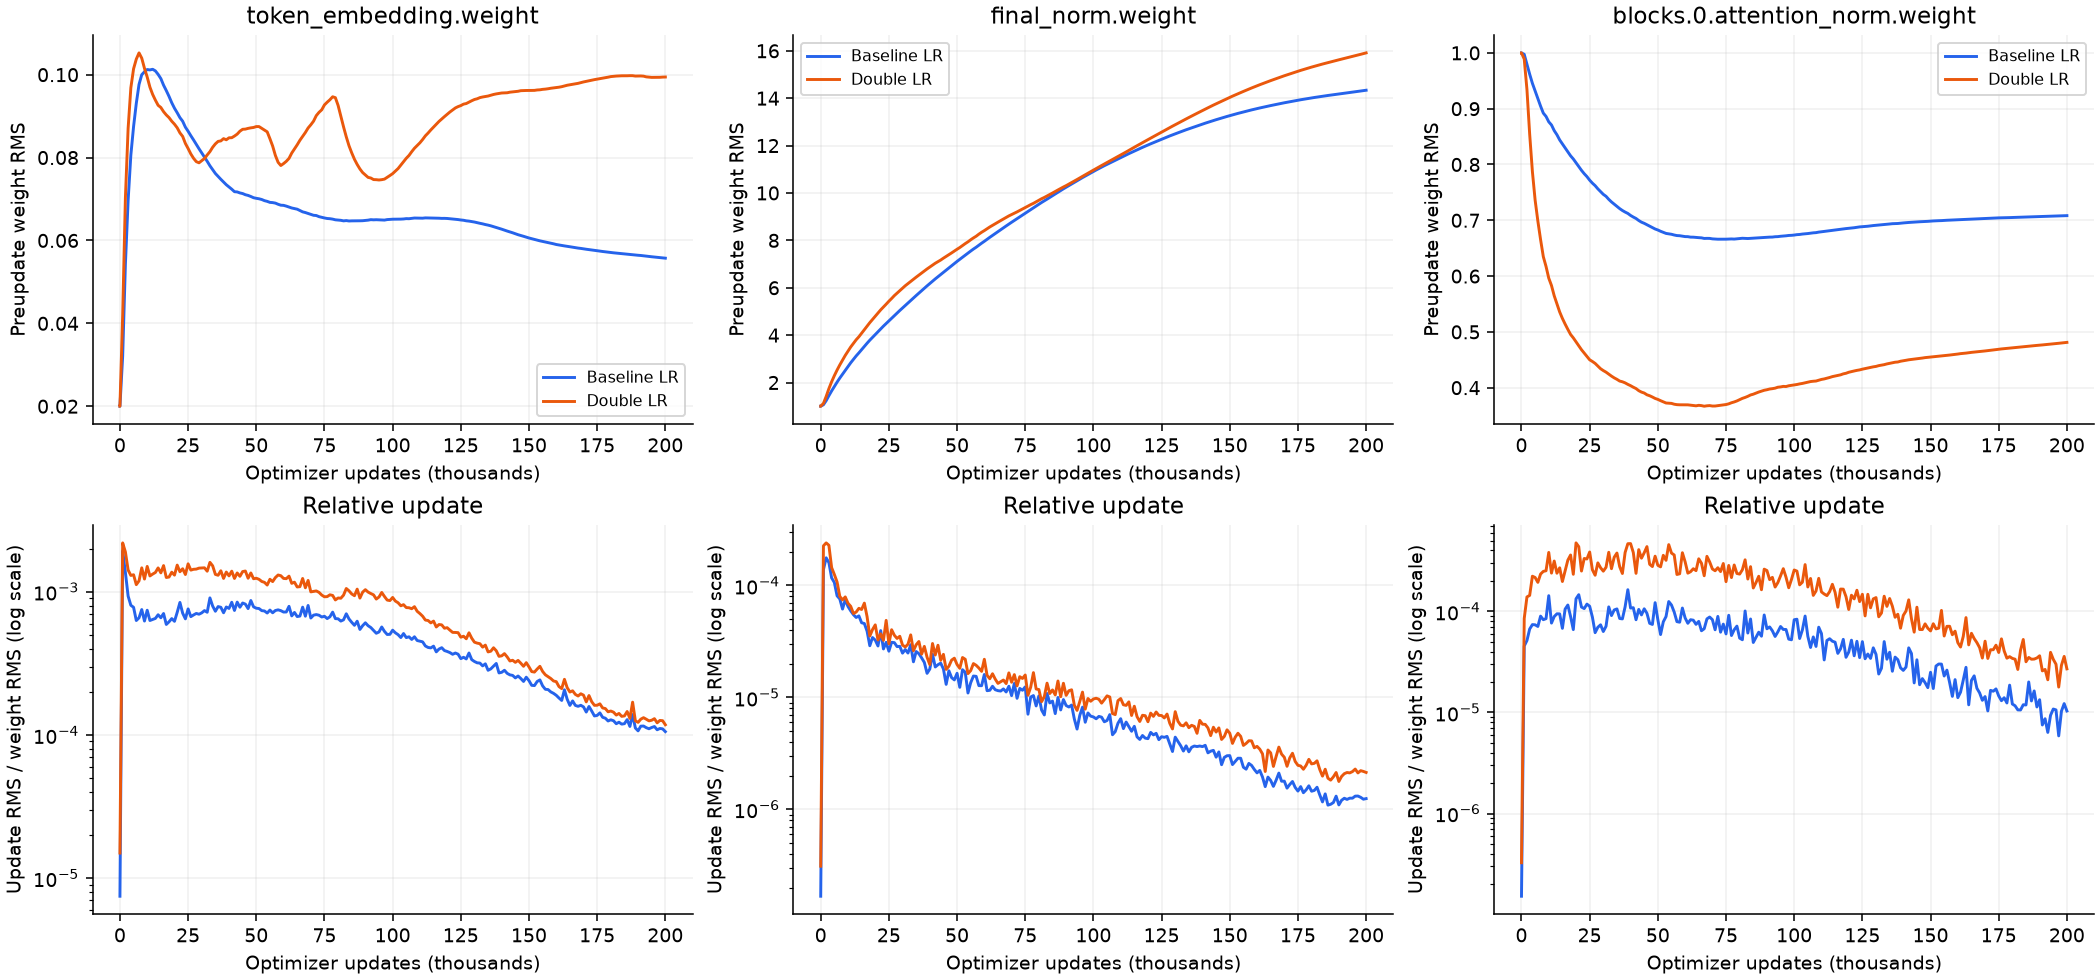

In [7]:
selected = ["token_embedding.weight", "final_norm.weight", "blocks.0.attention_norm.weight"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), constrained_layout=True)
for col, name in enumerate(selected):
    for run in runs:
        rows = run["stats"]
        axes[0, col].plot(steps(rows), [r["tensors"][name]["weight_rms"] for r in rows], color=run["color"], label=run["label"])
        sampled = rows[1:]
        axes[1, col].plot(steps(sampled), [r["tensors"][name]["relative_update"] for r in sampled], color=run["color"], label=run["label"])
    finish(axes[0, col], name, "Preupdate weight RMS")
    finish(axes[1, col], "Relative update", "Update RMS / weight RMS (log scale)")
    axes[1, col].set_yscale("log")
    axes[0, col].legend(fontsize=8)
plt.show()

In [8]:
print(f"{'Run':<15} {'Time (min)':>12} {'Timed stats (s)':>17} {'Time share':>12} {'JSONL (MB)':>12}")
for run in runs:
    elapsed = run["metrics"][-1]["elapsed_seconds"]
    recorded = sum(row["measurement_seconds"] for row in run["stats"])
    size = (run["path"] / "statistics.jsonl").stat().st_size / 1e6
    print(f"{run['label']:<15} {elapsed/60:12.2f} {recorded:17.2f} {100*recorded/elapsed:11.3f}% {size:12.2f}")
print("Timed statistics exclude per-update norm transfer/synchronization and file writing.")
print("This is not an estimate of incremental overhead; that needs a matched stats-off run.")

Run               Time (min)   Timed stats (s)   Time share   JSONL (MB)
Baseline LR            79.98              8.41       0.175%         2.38
Double LR              78.87              8.32       0.176%         2.38
Timed statistics exclude per-update norm transfer/synchronization and file writing.
This is not an estimate of incremental overhead; that needs a matched stats-off run.


### Findings and next experiment

- **Observed:** double LR learns faster early but has no clear final advantage. Final main-validation
  losses are 4.4902 versus 4.4972; last-10k means are 4.4736 versus 4.4841. Both best values occur at step 185,500.
- **Observed:** 99.42% versus 99.36% of updates exceed clip norm 1. Late mean raw norms rise to roughly 9.5 versus 8.0.
  All blocks still receive updates. The 128-element first attention projection bias contributes about
  26% of squared gradient norm on late sampled updates; embeddings contribute about 30% versus 38%.
- **Inference:** simply increasing LR is not a promising fix for this plateau. Clipping/scale dynamics
  are worth a controlled test, but these logs do not identify a cause or establish that accumulation would help.
- **Next:** use the baseline LR schedule and change only `grad_clip` from 1 to 5 for a fresh matched run.
  Compare held-out loss, clipping frequency, and actual updates. If it does not help, a tiny-corpus
  overfit check and a matched capacity experiment would distinguish more possibilities.

The two runs share one seed. Time windows and probe batches are not independent experimental repeats.
Gradient noise, activations, and logits were not logged; no conclusions about them are measured here.

## Clip-5 follow-up

The third run changes only the training clip threshold (1 → 5) and adds probes.
Previous runs lack the new fields; activation/noise/logit plots below describe clip-5 only.

Run              Final val   Best val   Last 10k    Clipped
Baseline LR        4.49021    4.44174    4.47358     99.42%
Double LR          4.49723    4.43942    4.48412     99.36%
Clip 5             4.49520    4.45187    4.48147     61.44%


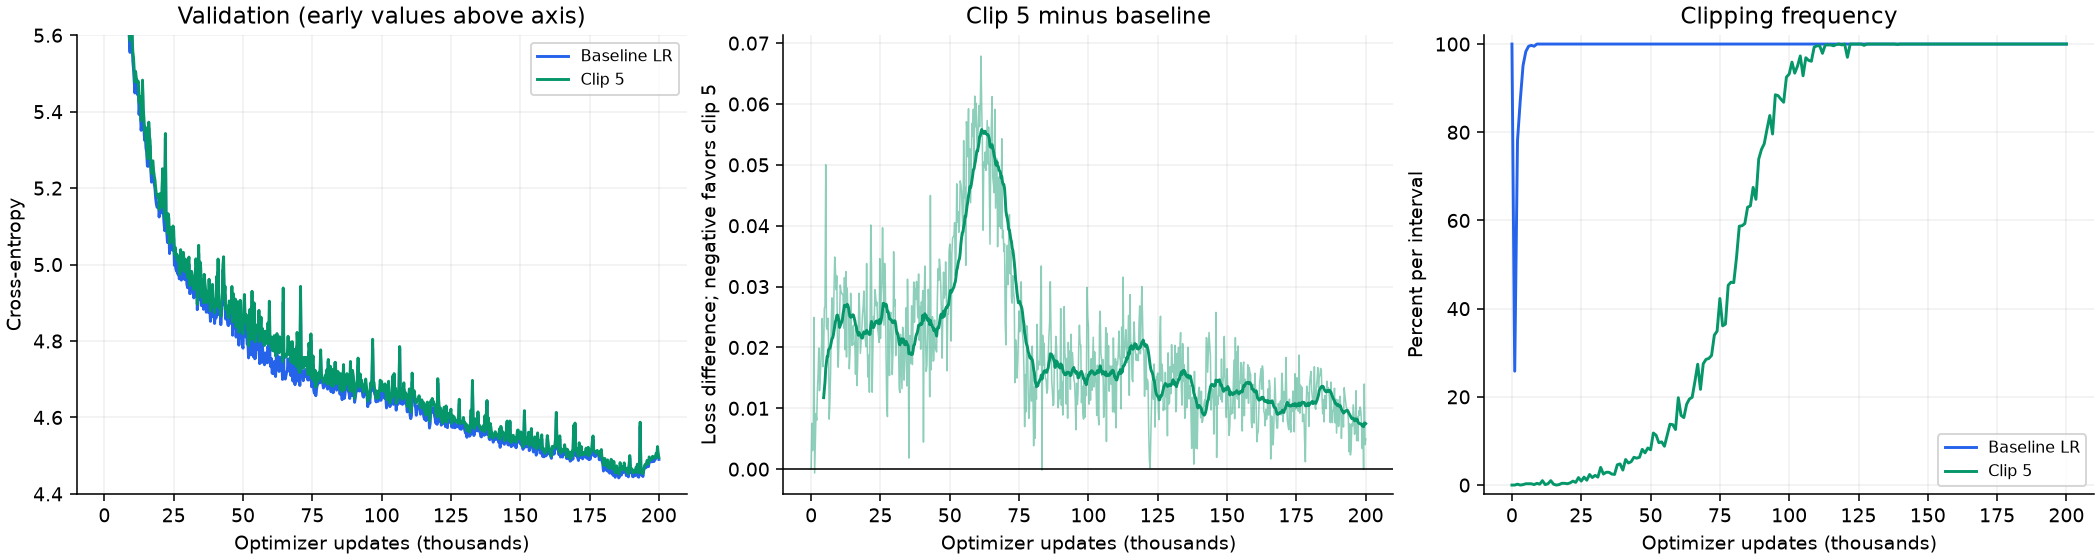

In [9]:
clip_name = "gpt-mlx-basic-diagnostics-clip5-01"
clip_path = root / "artifacts/pretraining" / clip_name
clip_meta = json.loads((clip_path / "metadata.json").read_text())
clip_stats = [json.loads(line) for line in (clip_path / "statistics.jsonl").read_text().splitlines()]
with (clip_path / "metrics.csv").open() as file:
    clip_metrics = [{key: float(value) if value else np.nan for key, value in row.items()}
                    for row in csv.DictReader(file)]
clip_run = dict(name=clip_name, label="Clip 5", color="#059669", path=clip_path,
                metadata=clip_meta, stats=clip_stats, metrics=clip_metrics)
assert clip_meta["status"] == "completed"
for field in ("model_config", "data_config", "tokenizer_sha256", "token_cache"):
    assert clip_meta[field] == a["metadata"][field], field
changes = {key for key in ta if ta[key] != clip_meta["training_config"][key]}
assert changes == {"grad_clip"}, changes
assert clip_stats[0]["tensors"] == a["stats"][0]["tensors"]
assert [row["step"] for row in clip_metrics] == [row["step"] for row in a["metrics"]]
assert sum(row["interval"]["updates"] for row in clip_stats) == 200000

print(f"{'Run':<15} {'Final val':>10} {'Best val':>10} {'Last 10k':>10} {'Clipped':>10}")
for run in (a, b, clip_run):
    count = sum(row["interval"]["updates"] for row in run["stats"])
    clipped = sum(row["interval"]["updates"] * (row["interval"]["clipped_fraction"] or 0)
                  for row in run["stats"]) / count
    print(f"{run['label']:<15} {run['metrics'][-1]['val_loss']:10.5f} "
          f"{min(row['val_loss'] for row in run['metrics']):10.5f} "
          f"{mean_val(run, 190000, 200000):10.5f} {100*clipped:9.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for run in (a, clip_run):
    axes[0].plot(steps(run["metrics"]), values(run["metrics"], "val_loss"), color=run["color"], label=run["label"])
    sampled = run["stats"][1:]
    axes[2].plot(steps(sampled), 100*values(sampled, "interval", "clipped_fraction"), color=run["color"], label=run["label"])
delta = values(clip_metrics, "val_loss") - values(a["metrics"], "val_loss")
axes[1].plot(steps(clip_metrics), delta, color=clip_run["color"], alpha=0.45, linewidth=0.8)
axes[1].plot(steps(clip_metrics)[19:], np.convolve(delta, np.ones(20)/20, mode="valid"), color=clip_run["color"])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[0].set(ylim=(4.4, 5.6))
finish(axes[0], "Validation (early values above axis)", "Cross-entropy")
finish(axes[1], "Clip 5 minus baseline", "Loss difference; negative favors clip 5")
finish(axes[2], "Clipping frequency", "Percent per interval")
axes[2].set_ylim(-2, 102)
for ax in (axes[0], axes[2]):
    ax.legend(fontsize=8)
plt.show()

**Result:** clip-5 lowers overall clipping to 61.44%, but is slightly worse on main validation
(final 4.4952 versus 4.4902; last-10k mean 4.4815 versus 4.4736). By the final 50k updates,
clip-5 is again clipping every update. This experiment does not support loosening clipping as a fix.

### Noise and gradient-direction agreement

Four batches of 2,560 tokens, raw gradients at identical weights, fixed probe windows.
Cosine agreement compares gradients across batches, not consecutive training updates.

Noise reports: 42 ; nonpositive signal estimates: 0
Late median noise/signal: 5.5999377552961125
Late median pairwise cosine: 0.1506569782892863
Final noise scale (tokens): 19904.14226767404


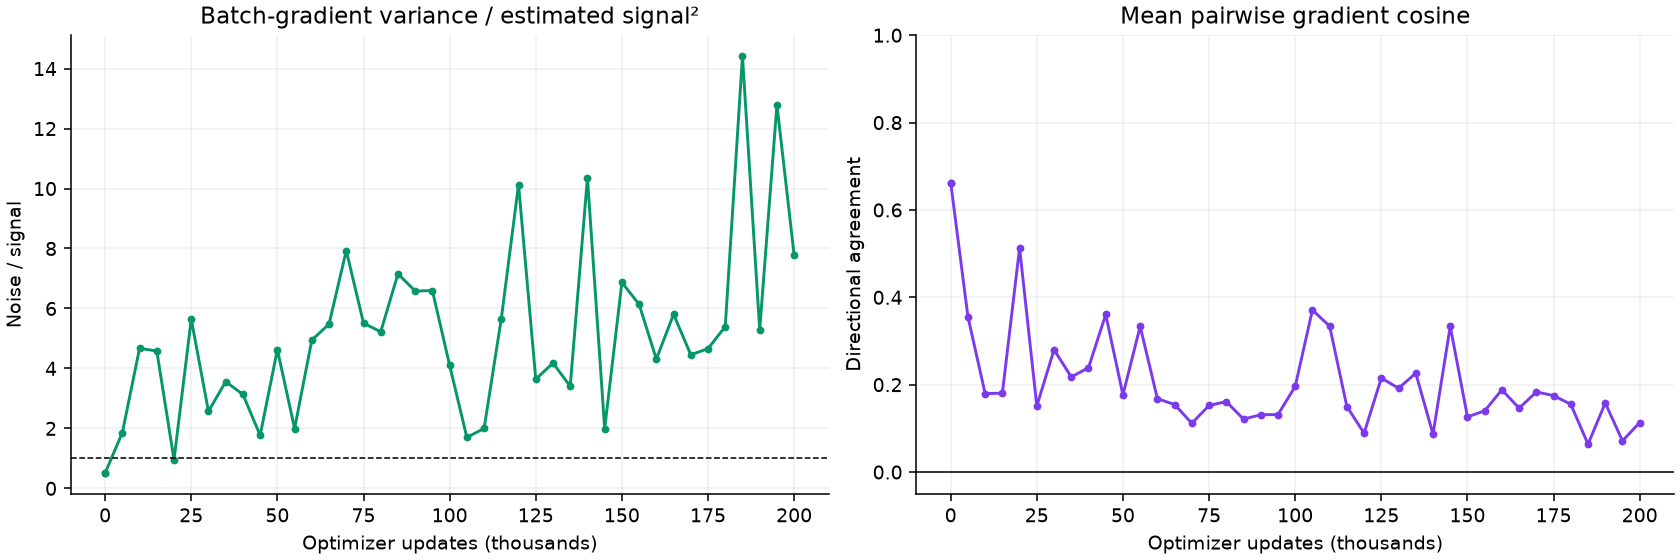

In [10]:
noise_rows = [row for row in clip_stats if "gradient_noise" in row]
noise_x = steps(noise_rows)
ratios = values(noise_rows, "gradient_noise", "noise_to_signal")
cosines = values(noise_rows, "gradient_noise", "mean_pairwise_cosine")
late = [row["gradient_noise"] for row in noise_rows if row["step"] > 150000]
print("Noise reports:", len(noise_rows), "; nonpositive signal estimates:",
      sum(row["gradient_noise"]["signal_squared_estimate"] <= 0 for row in noise_rows))
print("Late median noise/signal:", np.median([row["noise_to_signal"] for row in late]))
print("Late median pairwise cosine:", np.median([row["mean_pairwise_cosine"] for row in late]))
print("Final noise scale (tokens):", noise_rows[-1]["gradient_noise"]["noise_scale_tokens"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(noise_x, ratios, marker=".", color="#059669")
axes[0].axhline(1, color="black", linestyle="--", linewidth=0.8)
finish(axes[0], "Batch-gradient variance / estimated signal²", "Noise / signal")
axes[1].plot(noise_x, cosines, marker=".", color="#7c3aed")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylim(-0.05, 1)
finish(axes[1], "Mean pairwise gradient cosine", "Directional agreement")
plt.show()

Late median noise/signal is about 5.6 and cosine agreement about 0.15. The final token-scaled
noise estimate is about 19.9k tokens versus the current 2.56k-token batch. This supports testing
larger effective batches, not selecting an exact optimum: there are only four fixed probe batches,
tokens are correlated, and these are raw gradients before clipping/Adam.

### Activations: first attention branch cancels much of its input

For same-shaped vectors `x`, `u`, and residual `x+u`, their flattened cosine follows directly from RMS:
`(RMS(x+u)² - RMS(x)² - RMS(u)²) / (2*RMS(x)*RMS(u))`.

Final first-attention activation cosine: -0.9415833693169638


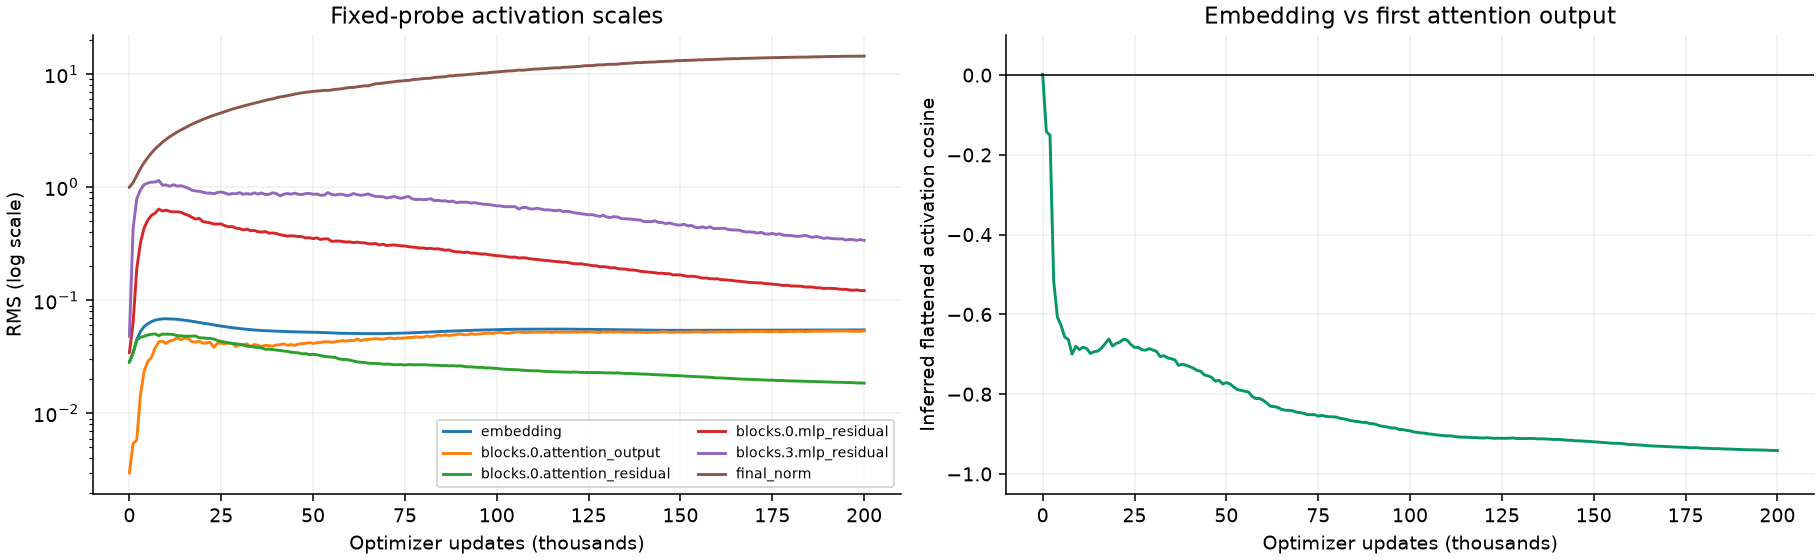

In [11]:
activation_names = ["embedding", "blocks.0.attention_output", "blocks.0.attention_residual",
                    "blocks.0.mlp_residual", "blocks.3.mlp_residual", "final_norm"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for name in activation_names:
    y = [row["probes"]["activations"][name]["rms"] for row in clip_stats]
    axes[0].plot(steps(clip_stats), y, label=name)
axes[0].set_yscale("log")
finish(axes[0], "Fixed-probe activation scales", "RMS (log scale)")
axes[0].legend(fontsize=7, ncol=2)
cosines = []
for row in clip_stats:
    act = row["probes"]["activations"]
    x = act["embedding"]["rms"]
    u = act["blocks.0.attention_output"]["rms"]
    residual = act["blocks.0.attention_residual"]["rms"]
    cosines.append((residual**2 - x**2 - u**2) / (2*x*u))
axes[1].plot(steps(clip_stats), cosines, color="#059669")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylim(-1.05, 0.1)
finish(axes[1], "Embedding vs first attention output", "Inferred flattened activation cosine")
plt.show()
print("Final first-attention activation cosine:", cosines[-1])

At the final probe, embedding RMS is 0.0548 and attention-output RMS 0.0536, but their sum
has RMS 0.0185; inferred cosine is −0.942. The branch has learned strong cancellation.
This may contribute to scale sensitivity around the following normalization, but is not proof of a bug
or the plateau's cause. These are forward activations, not backward activation gradients.

### Logits: raw scale is not confidence

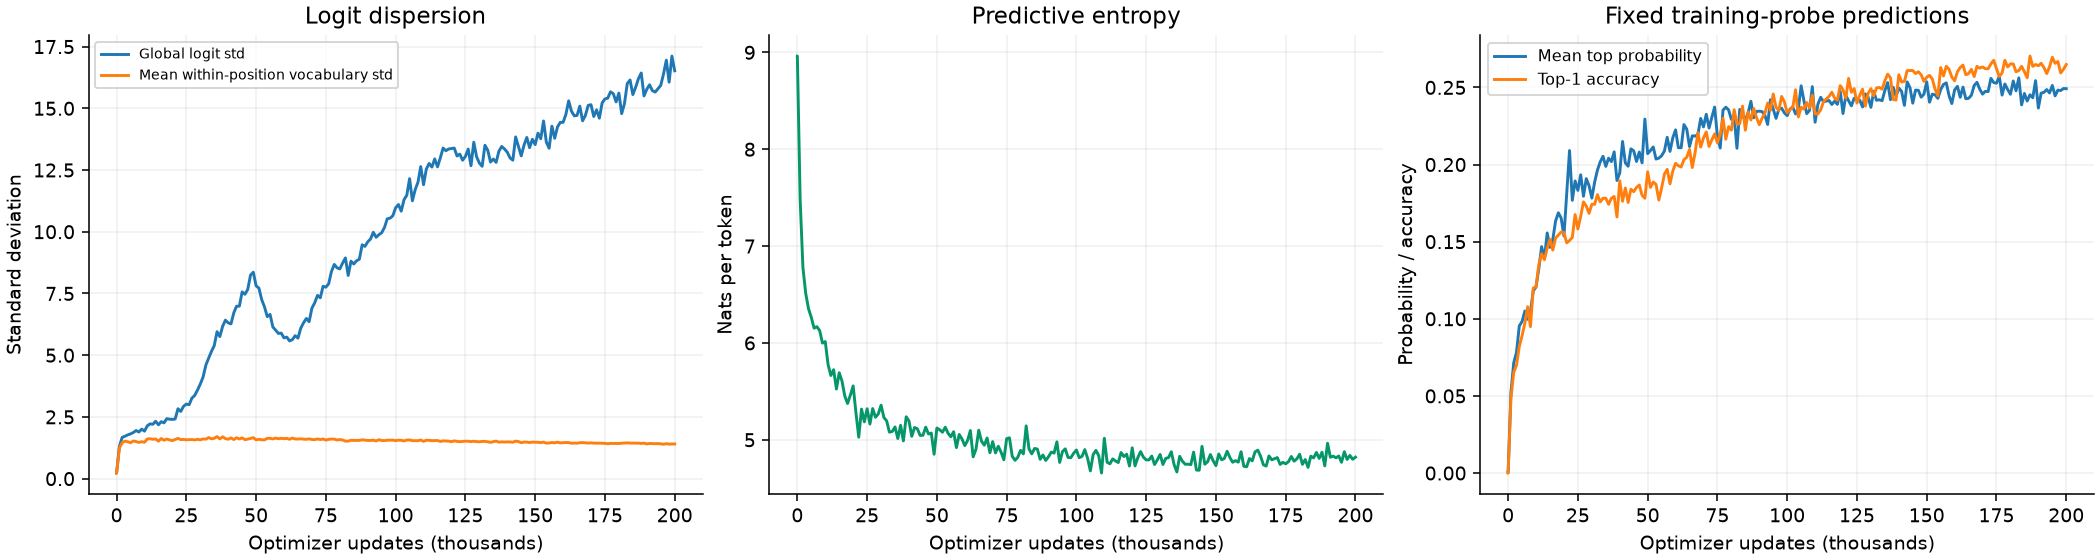

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for field, label in [("std", "Global logit std"), ("vocabulary_std_mean", "Mean within-position vocabulary std")]:
    axes[0].plot(steps(clip_stats), values(clip_stats, "probes", "logits", field), label=label)
axes[1].plot(steps(clip_stats), values(clip_stats, "probes", "logits", "entropy_mean"), color="#059669")
for field, label in [("max_probability_mean", "Mean top probability"), ("top1_accuracy", "Top-1 accuracy")]:
    axes[2].plot(steps(clip_stats), values(clip_stats, "probes", "logits", field), label=label)
finish(axes[0], "Logit dispersion", "Standard deviation")
finish(axes[1], "Predictive entropy", "Nats per token")
finish(axes[2], "Fixed training-probe predictions", "Probability / accuracy")
axes[0].legend(fontsize=7)
axes[2].legend(fontsize=8)
plt.show()

Global logit standard deviation grows to 16.52, while mean within-position vocabulary std is
only 1.40. Per-position common offsets do not affect softmax; large raw scale alone does not show
probability saturation. Final mean entropy is 4.82 nats, mean top probability 0.249, and top-1 accuracy
0.265 on this training probe. This is not held-out accuracy or a calibration assessment.

**Next experiment:** return to baseline `grad_clip = 1` and test accumulation factor 4 at the same
effective token budget, with a token-matched LR schedule. That is 10,240 tokens/update and 50k
optimizer updates for 512M training tokens. Start with the same LR as a controlled first comparison;
larger-batch LR retuning can follow. Gradient accumulation has not been implemented by this analysis.

## Accumulation ×4 results

Compare by **training tokens**, since this run has 50k updates of 10,240 tokens,
versus 200k updates of 2,560 tokens. All runs process 512M training tokens.

Run                  Updates  Final val   Best val      PPL   Time/min
Baseline LR           200000    4.49021    4.44174    89.14      79.98
Double LR             200000    4.49723    4.43942    89.77      78.87
Clip 5                200000    4.49520    4.45187    89.59      80.53
Accumulation ×4        50000    4.36453    4.35093    78.61      84.97
0.0–128.0M tokens: matched mean Δ=+0.13882; accumulation wins 32% of 100 evaluations
128.0–256.0M tokens: matched mean Δ=-0.09347; accumulation wins 100% of 100 evaluations
256.0–384.0M tokens: matched mean Δ=-0.11769; accumulation wins 100% of 100 evaluations
384.0–512.0M tokens: matched mean Δ=-0.10673; accumulation wins 100% of 100 evaluations
486.4–512.0M tokens: matched mean Δ=-0.11020; accumulation wins 100% of 20 evaluations


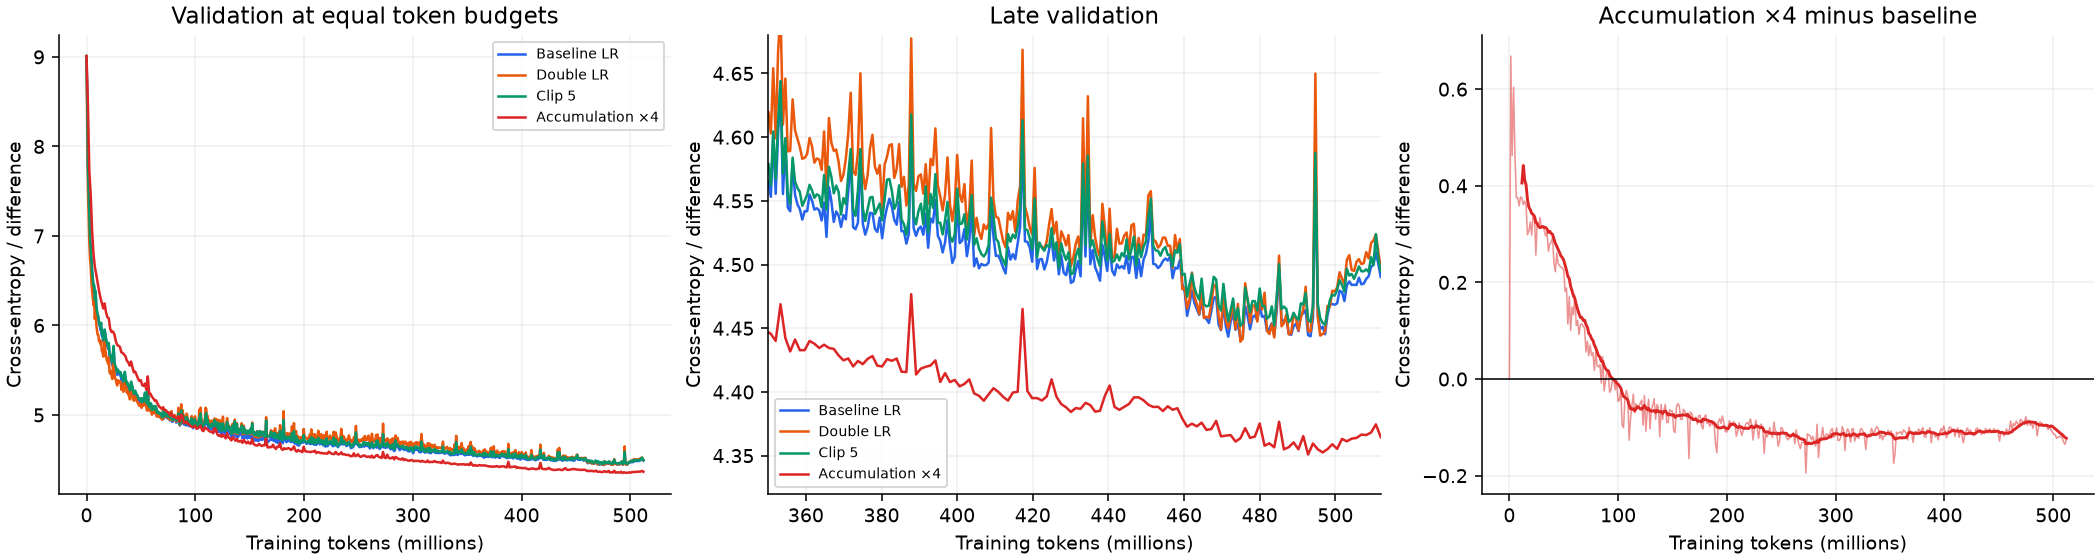

In [13]:
accum_name = "gpt-mlx-basic-diagnostics-accum4-01"
accum_path = root / "artifacts/pretraining" / accum_name
accum_meta = json.loads((accum_path / "metadata.json").read_text())
accum_stats = [json.loads(line) for line in (accum_path / "statistics.jsonl").read_text().splitlines()]
with (accum_path / "metrics.csv").open() as file:
    accum_metrics = [{key: float(value) if value else np.nan for key, value in row.items()}
                     for row in csv.DictReader(file)]
accum_run = dict(name=accum_name, label="Accumulation ×4", color="#dc2626", path=accum_path,
                 metadata=accum_meta, stats=accum_stats, metrics=accum_metrics)
assert accum_meta["status"] == "completed"
for field in ("model_config", "data_config", "tokenizer_sha256", "token_cache"):
    assert accum_meta[field] == a["metadata"][field], field
assert accum_stats[0]["tensors"] == a["stats"][0]["tensors"]
at = accum_meta["training_config"]
assert at["gradient_accumulation_steps"] == 4
for field in ("steps", "warmup_steps", "lr_decay_steps"):
    assert at[field] * 4 == ta[field], field
for field in ("batch_size", "learning_rate", "min_learning_rate", "grad_clip", "seed",
              "weight_decay", "sampling", "compile_step", "lr_schedule"):
    assert at[field] == ta[field], field

def tokens_per_update(run):
    train_config = run["metadata"]["training_config"]
    return (train_config["batch_size"] * train_config.get("gradient_accumulation_steps", 1)
            * run["metadata"]["model_config"]["context_length"])

def token_x(run, rows):
    return values(rows, "step") * tokens_per_update(run) / 1e6

all_runs = [a, b, clip_run, accum_run]
print(f"{'Run':<18} {'Updates':>9} {'Final val':>10} {'Best val':>10} {'PPL':>8} {'Time/min':>10}")
for run in all_runs:
    assert run["metrics"][-1]["step"] * tokens_per_update(run) == 512000000
    assert sum(row["interval"]["updates"] for row in run["stats"]) == run["metadata"]["training_config"]["steps"]
    final = run["metrics"][-1]["val_loss"]
    print(f"{run['label']:<18} {int(run['metrics'][-1]['step']):9d} {final:10.5f} "
          f"{min(row['val_loss'] for row in run['metrics']):10.5f} {math.exp(final):8.2f} "
          f"{run['metrics'][-1]['elapsed_seconds']/60:10.2f}")

base_by_token = {int(row["step"]) * tokens_per_update(a): row["val_loss"] for row in a["metrics"]}
accum_by_token = {int(row["step"]) * tokens_per_update(accum_run): row["val_loss"] for row in accum_metrics}
common_tokens = sorted(base_by_token.keys() & accum_by_token.keys())
matched_delta = np.array([accum_by_token[t] - base_by_token[t] for t in common_tokens])
for lo, hi in [(0, 128e6), (128e6, 256e6), (256e6, 384e6), (384e6, 512e6), (486.4e6, 512e6)]:
    selected = [i for i, t in enumerate(common_tokens) if lo < t <= hi]
    delta = matched_delta[selected]
    print(f"{lo/1e6:.1f}–{hi/1e6:.1f}M tokens: matched mean Δ={delta.mean():+.5f}; "
          f"accumulation wins {np.mean(delta < 0):.0%} of {len(selected)} evaluations")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for run in all_runs:
    for ax in axes[:2]:
        ax.plot(token_x(run, run["metrics"]), values(run["metrics"], "val_loss"),
                color=run["color"], label=run["label"], linewidth=1.3)
axes[1].set(xlim=(350, 512), ylim=(4.32, 4.68))
axes[2].plot(np.array(common_tokens)/1e6, matched_delta, color=accum_run["color"], alpha=0.5, linewidth=0.8)
axes[2].plot(np.array(common_tokens)[9:]/1e6, np.convolve(matched_delta, np.ones(10)/10, mode="valid"), color=accum_run["color"])
axes[2].axhline(0, color="black", linewidth=0.8)
for ax, title in zip(axes, ["Validation at equal token budgets", "Late validation", "Accumulation ×4 minus baseline"]):
    ax.set(title=title, xlabel="Training tokens (millions)", ylabel="Cross-entropy / difference")
for ax in axes[:2]:
    ax.legend(fontsize=7)
plt.show()

**Observed improvement:** final validation 4.3645 versus baseline 4.4902 (−0.1257 nats/token),
equivalent to perplexity 78.61 versus 89.14, about 11.8% lower. The final 25.6M-token window
improves by 0.1102 on exactly matched evaluations. Accumulation is slower early but wins every
matched evaluation after 128M tokens. Both fixed probes improve: train 4.2618 versus 4.3711,
held-out 4.1778 versus 4.2896. Generated samples still contain broken grammar and incoherent text.

### Noise: the larger batch does not eliminate late noise

The baseline lacks noise probes. The curves below compare clip-5 with accumulation at different
trained weights; they cannot isolate batch size alone. Only their initialization shares identical weights.

Clip 5 late median noise/signal: 5.5999377552961125 late median cosine: 0.1506569782892863
Accumulation ×4 late median noise/signal: 5.071848449188444 late median cosine: 0.16602259874343872


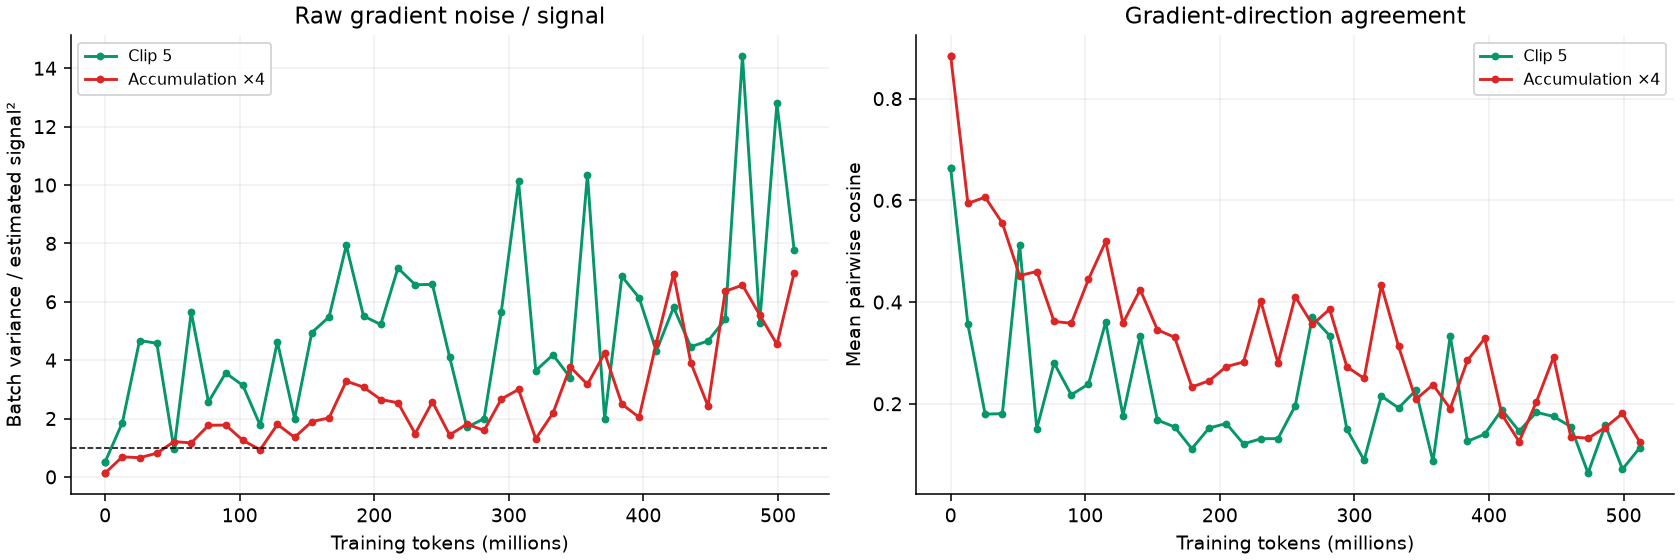

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for run in (clip_run, accum_run):
    rows = [row for row in run["stats"] if "gradient_noise" in row]
    axes[0].plot(token_x(run, rows), values(rows, "gradient_noise", "noise_to_signal"), marker=".", color=run["color"], label=run["label"])
    axes[1].plot(token_x(run, rows), values(rows, "gradient_noise", "mean_pairwise_cosine"), marker=".", color=run["color"], label=run["label"])
    late = [row["gradient_noise"] for row in rows if row["step"] * tokens_per_update(run) > 384e6]
    print(run["label"], "late median noise/signal:", np.median([row["noise_to_signal"] for row in late]),
          "late median cosine:", np.median([row["mean_pairwise_cosine"] for row in late]))
axes[0].axhline(1, color="black", linewidth=0.8, linestyle="--")
for ax, title, ylabel in zip(axes, ["Raw gradient noise / signal", "Gradient-direction agreement"],
                             ["Batch variance / estimated signal²", "Mean pairwise cosine"]):
    ax.set(title=title, xlabel="Training tokens (millions)", ylabel=ylabel)
    ax.legend(fontsize=8)
plt.show()

At initialization, quadrupling the batch reduces measured noise/signal from 0.511 to 0.132,
consistent with averaging. Late in training, accumulation's median is still 5.07 (clip-5: 5.60),
with median cosine 0.166 (clip-5: 0.151). The final 71.6k-token noise-scale estimate is not an
instruction to set that batch size: it is noisy, based on four fixed batches, and not Adam-aware.

### Parameter and activation scales follow a different trajectory

Clip 5 final first-attention activation cosine: -0.9415833693169638
Accumulation ×4 final first-attention activation cosine: -0.44597339629437355


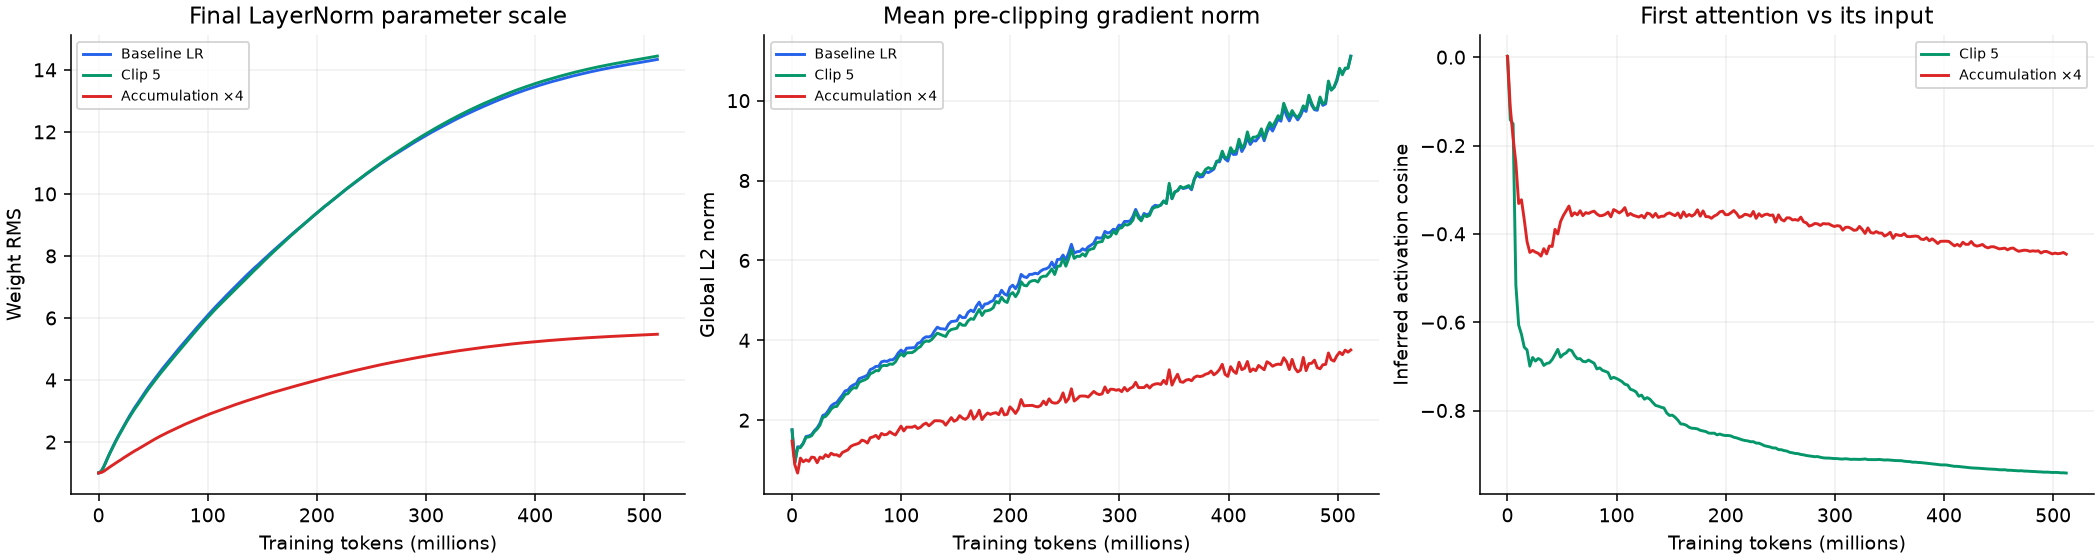

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for run in (a, clip_run, accum_run):
    rows = run["stats"]
    axes[0].plot(token_x(run, rows), [row["tensors"]["final_norm.weight"]["weight_rms"] for row in rows], color=run["color"], label=run["label"])
    axes[1].plot(token_x(run, rows[1:]), values(rows[1:], "interval", "gradient_norm_mean"), color=run["color"], label=run["label"])
for run in (clip_run, accum_run):
    cosines = []
    for row in run["stats"]:
        act = row["probes"]["activations"]
        x = act["embedding"]["rms"]
        u = act["blocks.0.attention_output"]["rms"]
        residual = act["blocks.0.attention_residual"]["rms"]
        cosines.append((residual**2 - x**2 - u**2)/(2*x*u))
    axes[2].plot(token_x(run, run["stats"]), cosines, color=run["color"], label=run["label"])
    print(run["label"], "final first-attention activation cosine:", cosines[-1])
for ax, title, ylabel in zip(axes, ["Final LayerNorm parameter scale", "Mean pre-clipping gradient norm", "First attention vs its input"],
                             ["Weight RMS", "Global L2 norm", "Inferred activation cosine"]):
    ax.set(title=title, xlabel="Training tokens (millions)", ylabel=ylabel)
    ax.legend(fontsize=7)
plt.show()

Final LayerNorm weight RMS is 5.48 with accumulation versus 14.34 in baseline. The first
attention branch's inferred input/output cosine is −0.446 versus clip-5's −0.942: much weaker
cancellation. Smaller gradient norms therefore reflect both batching and a different trained model;
they are not a direct noise measurement.

**Interpretation:** accumulation ×4 is the strongest tested configuration at 512M tokens and is a good
new baseline. This single-seed comparison does not identify noise reduction as the sole mechanism:
there are four times fewer Adam updates, a longer token-scale momentum history, and less cumulative
weight decay at unchanged per-update settings. Runtime is about 85 versus 80 minutes, not a speedup.
There is no clear final downward trend that guarantees a longer continuation will help.

Calculated from the saved LR schedules, the **weight-decay-only** matrix multiplier
`product(1 - learning_rate * weight_decay)` is 0.0370 in baseline versus 0.4386 with accumulation.
These are not actual measured weight shrinkages: gradient updates also act, and LayerNorm vectors
are excluded from decay. They quantify a substantial change in the regularization budget.

A second seed would test reproducibility. To separate reduced regularization from averaging, a
follow-up accumulated run with `weight_decay = 0.4` would approximately restore baseline cumulative
decay. Longer training or a larger model are separate questions; neither has been evaluated here.

## Accumulation ×8 results

Same 512M training tokens and LR range, with 25k optimizer updates of 20,480 tokens.
Warmup and decay endpoints match by tokens; validation uses unchanged windows.

Run                 Final val   Best val      PPL   Time/min
Baseline LR           4.49021    4.44174    89.14      79.98
Accumulation ×4       4.36453    4.35093    78.61      84.97
Accumulation ×8       4.41616    4.40914    82.78      74.11
0.0–128.0M tokens: ×8 minus ×4 mean Δ=+0.19862; ×8 wins 0% of 50 evaluations
128.0–256.0M tokens: ×8 minus ×4 mean Δ=+0.08184; ×8 wins 0% of 50 evaluations
256.0–384.0M tokens: ×8 minus ×4 mean Δ=+0.05179; ×8 wins 0% of 50 evaluations
384.0–512.0M tokens: ×8 minus ×4 mean Δ=+0.05386; ×8 wins 0% of 50 evaluations
486.4–512.0M tokens: ×8 minus ×4 mean Δ=+0.05392; ×8 wins 0% of 10 evaluations


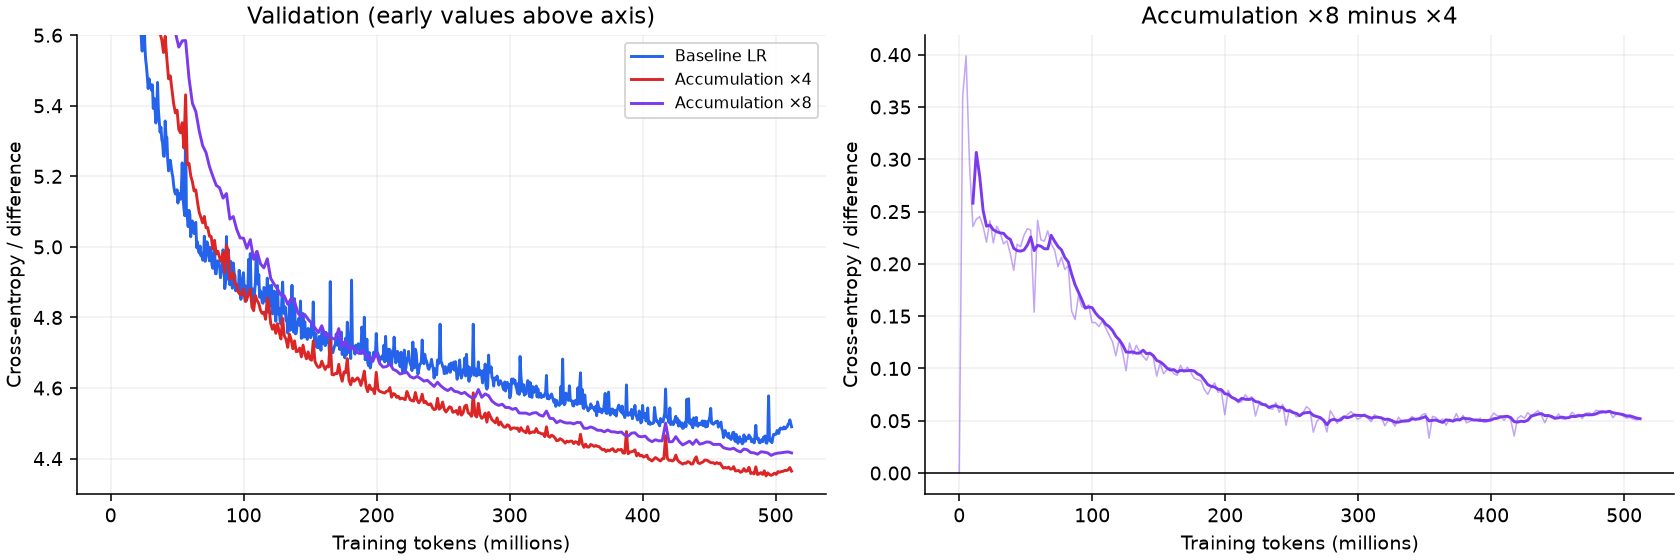

In [16]:
accum8_name = "gpt-mlx-basic-diagnostics-accum8-01"
accum8_path = root / "artifacts/pretraining" / accum8_name
accum8_meta = json.loads((accum8_path / "metadata.json").read_text())
accum8_stats = [json.loads(line) for line in (accum8_path / "statistics.jsonl").read_text().splitlines()]
with (accum8_path / "metrics.csv").open() as file:
    accum8_metrics = [{key: float(value) if value else np.nan for key, value in row.items()}
                     for row in csv.DictReader(file)]
accum8_run = dict(name=accum8_name, label="Accumulation ×8", color="#7c3aed", path=accum8_path,
                  metadata=accum8_meta, stats=accum8_stats, metrics=accum8_metrics)
assert accum8_meta["status"] == "completed"
assert accum8_metrics[-1]["step"] * tokens_per_update(accum8_run) == 512000000
assert sum(row["interval"]["updates"] for row in accum8_stats) == 25000
for field in ("model_config", "data_config", "tokenizer_sha256", "token_cache"):
    assert accum8_meta[field] == accum_meta[field], field
assert accum8_stats[0]["tensors"] == accum_stats[0]["tensors"]
train8 = accum8_meta["training_config"]
for field in ("steps", "warmup_steps", "lr_decay_steps"):
    assert train8[field] * 2 == at[field], field
for field in ("batch_size", "learning_rate", "min_learning_rate", "grad_clip", "weight_decay", "seed"):
    assert train8[field] == at[field], field

print(f"{'Run':<18} {'Final val':>10} {'Best val':>10} {'PPL':>8} {'Time/min':>10}")
for run in (a, accum_run, accum8_run):
    final = run["metrics"][-1]["val_loss"]
    print(f"{run['label']:<18} {final:10.5f} {min(row['val_loss'] for row in run['metrics']):10.5f} "
          f"{math.exp(final):8.2f} {run['metrics'][-1]['elapsed_seconds']/60:10.2f}")

by_token8 = {int(row["step"]) * tokens_per_update(accum8_run): row["val_loss"] for row in accum8_metrics}
matched = sorted(accum_by_token.keys() & by_token8.keys())
delta8 = np.array([by_token8[t] - accum_by_token[t] for t in matched])
for lo, hi in [(0, 128e6), (128e6, 256e6), (256e6, 384e6), (384e6, 512e6), (486.4e6, 512e6)]:
    delta = np.array([by_token8[t] - accum_by_token[t] for t in matched if lo < t <= hi])
    print(f"{lo/1e6:.1f}–{hi/1e6:.1f}M tokens: ×8 minus ×4 mean Δ={delta.mean():+.5f}; "
          f"×8 wins {np.mean(delta < 0):.0%} of {len(delta)} evaluations")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for run in (a, accum_run, accum8_run):
    axes[0].plot(token_x(run, run["metrics"]), values(run["metrics"], "val_loss"), color=run["color"], label=run["label"])
axes[0].set_ylim(4.3, 5.6)
axes[0].legend(fontsize=8)
axes[1].plot(np.array(matched)/1e6, delta8, color="#7c3aed", alpha=0.45, linewidth=0.8)
axes[1].plot(np.array(matched)[4:]/1e6, np.convolve(delta8, np.ones(5)/5, mode="valid"), color="#7c3aed")
axes[1].axhline(0, color="black", linewidth=0.8)
for ax, title in zip(axes, ["Validation (early values above axis)", "Accumulation ×8 minus ×4"]):
    ax.set(title=title, xlabel="Training tokens (millions)", ylabel="Cross-entropy / difference")
plt.show()

Accumulation ×4 late median noise/signal: 5.071848449188444 late median cosine: 0.16602259874343872
Accumulation ×8 late median noise/signal: 1.6958709043501436 late median cosine: 0.3708266019821167


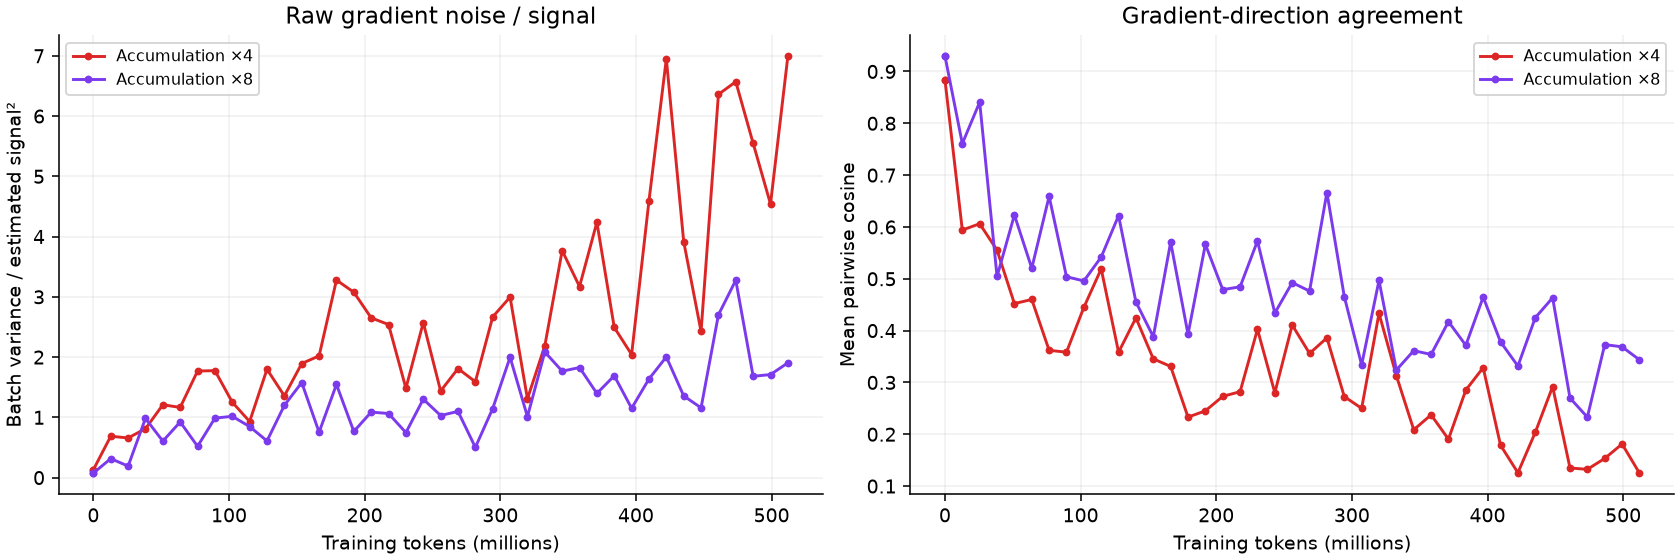

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for run in (accum_run, accum8_run):
    rows = [row for row in run["stats"] if "gradient_noise" in row]
    axes[0].plot(token_x(run, rows), values(rows, "gradient_noise", "noise_to_signal"), marker=".", color=run["color"], label=run["label"])
    axes[1].plot(token_x(run, rows), values(rows, "gradient_noise", "mean_pairwise_cosine"), marker=".", color=run["color"], label=run["label"])
    late = [row["gradient_noise"] for row in rows if row["step"] * tokens_per_update(run) > 384e6]
    print(run["label"], "late median noise/signal:", np.median([row["noise_to_signal"] for row in late]),
          "late median cosine:", np.median([row["mean_pairwise_cosine"] for row in late]))
for ax, title in zip(axes, ["Raw gradient noise / signal", "Gradient-direction agreement"]):
    ax.set(title=title, xlabel="Training tokens (millions)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Batch variance / estimated signal²")
axes[1].set_ylabel("Mean pairwise cosine")
plt.show()

**Result:** ×8 improves on baseline ×1 but trails ×4 at every matched evaluation after
initialization. Final validation is 4.4162 versus ×4's 4.3645; both fixed probes also favor ×4.
For the final 25.6M tokens, the matched mean difference is +0.0539. Thus ×4 remains the best tested
configuration at this budget and LR schedule.

**Noise:** late median raw noise/signal falls from 5.07 to 1.70, while gradient cosine rises
from 0.166 to 0.371. These are measurements along different trained trajectories, not a fixed-weight
causal comparison. Improved gradient consistency has not translated into better loss at unchanged LR
and half as many optimizer updates. It does not show that larger batches are intrinsically worse.

**Next hypothesis:** ×8 may benefit from larger useful steps. Test the same ×8 setup with
`learning_rate = 0.0006`, `min_learning_rate = 0.00006`, and `weight_decay = 0.05`.
This doubles LR while preserving its product with weight decay, holding each update's decay factor
constant relative to the current ×8 run. This is proposed, not an executed experiment.
Observed runtime was 74.11min versus ×4's 84.97min; hardware conditions and reporting differ,
so this is not a controlled speed result.

## Higher-LR ×8 results

Peak/floor LR doubles to `6e-4 / 6e-5`; weight decay halves to `0.05`.
All other settings match the original ×8 run, preserving the per-update decay factor.

Run                 Final val   Best val      PPL   Time/min
Baseline LR           4.49021    4.44174    89.14      79.98
Accumulation ×4       4.36453    4.35093    78.61      84.97
Accumulation ×8       4.41616    4.40914    82.78      74.11
×8, double LR         4.31443    4.30094    74.77      72.70
Versus Accumulation ×4: wins 100% of matched evaluations after first update; last25.6M matched mean Δ=-0.04959
Versus Accumulation ×8: wins 100% of matched evaluations after first update; last25.6M matched mean Δ=-0.10351


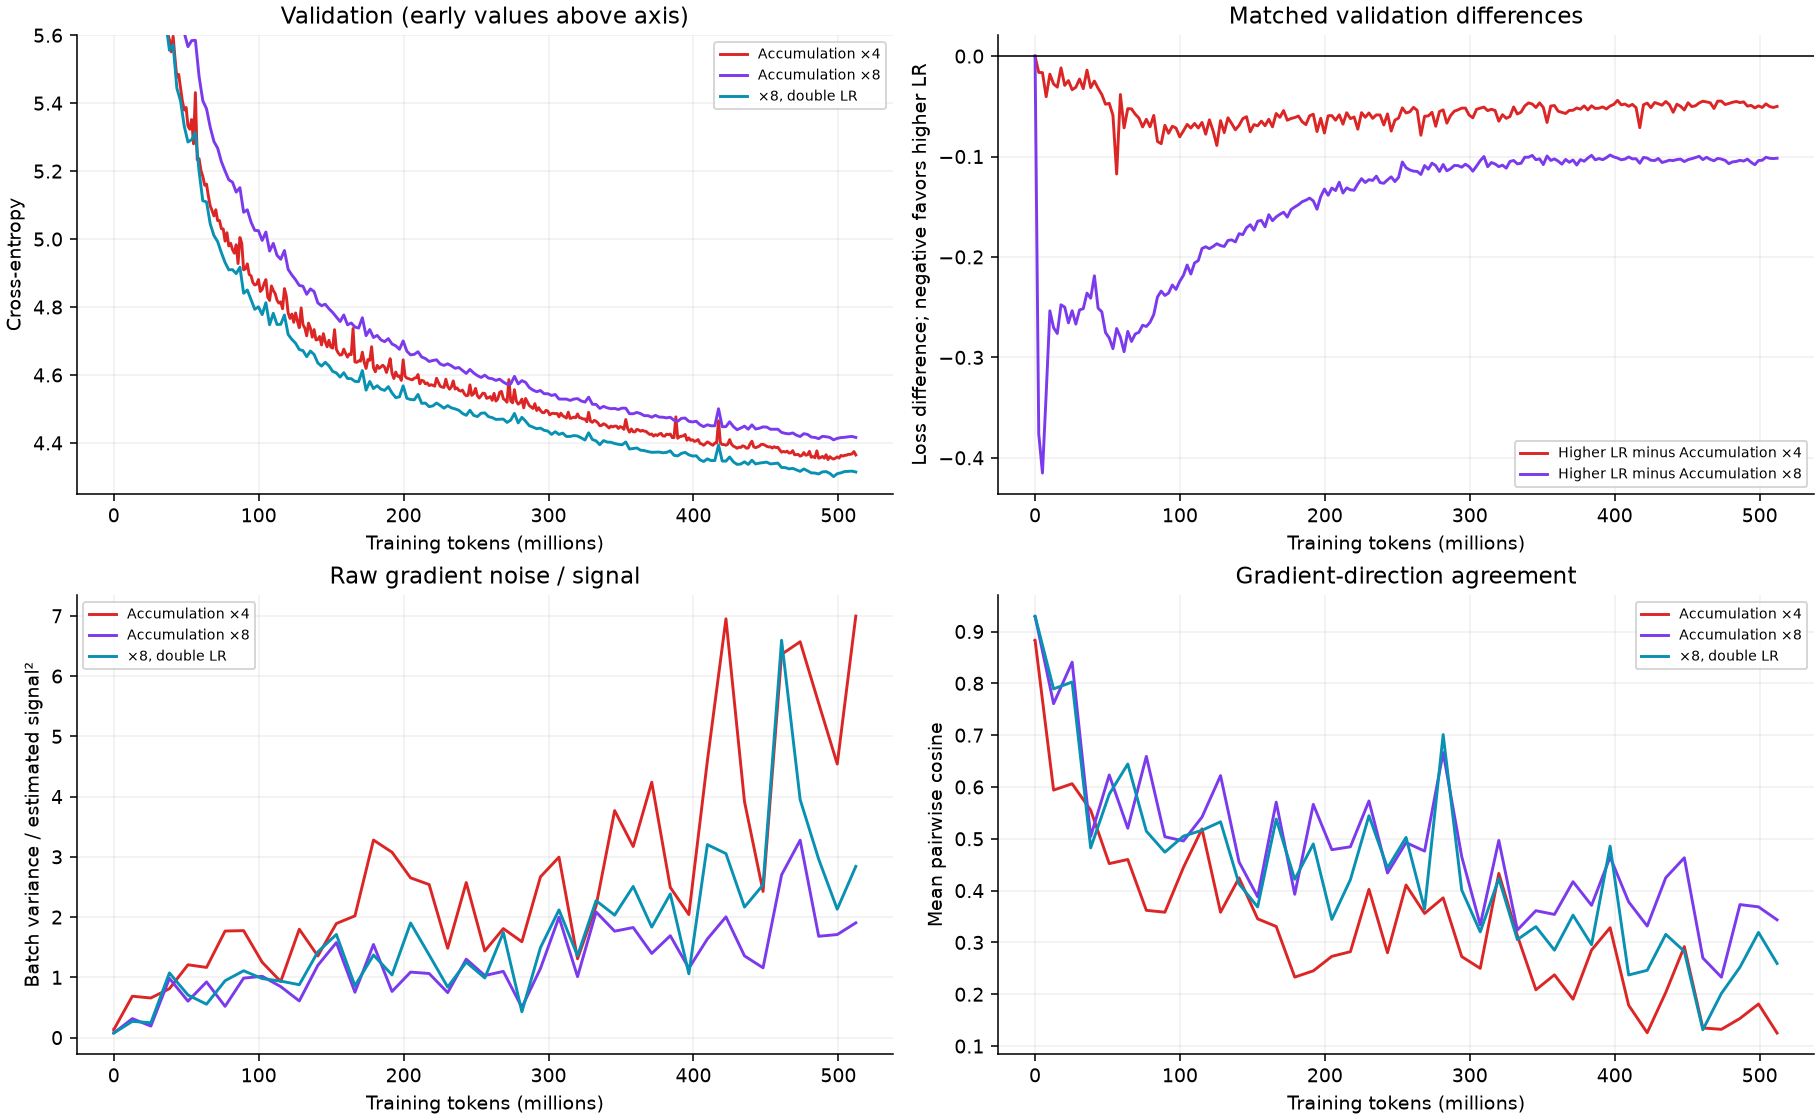

In [18]:
higher_name = "gpt-mlx-basic-diagnostics-accum8-lr2x-01"
higher_path = root / "artifacts/pretraining" / higher_name
higher_meta = json.loads((higher_path / "metadata.json").read_text())
higher_stats = [json.loads(line) for line in (higher_path / "statistics.jsonl").read_text().splitlines()]
with (higher_path / "metrics.csv").open() as file:
    higher_metrics = [{key: float(value) if value else np.nan for key, value in row.items()}
                      for row in csv.DictReader(file)]
higher = dict(name=higher_name, label="×8, double LR", color="#0891b2", path=higher_path,
              metadata=higher_meta, stats=higher_stats, metrics=higher_metrics)
assert higher_meta["status"] == "completed"
for key in ("model_config", "data_config", "tokenizer_sha256", "token_cache"):
    assert higher_meta[key] == accum8_meta[key], key
assert higher_stats[0]["tensors"] == accum8_stats[0]["tensors"]
ht = higher_meta["training_config"]
assert {key for key in ht if ht[key] != train8[key]} == {"learning_rate", "min_learning_rate", "weight_decay"}
for key in ("learning_rate", "min_learning_rate"):
    assert ht[key] == 2 * train8[key]
    assert ht[key] * ht["weight_decay"] == train8[key] * train8["weight_decay"]
assert higher_metrics[-1]["step"] * tokens_per_update(higher) == 512000000
assert [row["step"] for row in higher_metrics] == [row["step"] for row in accum8_metrics]
assert sum(row["interval"]["updates"] for row in higher_stats) == 25000

print(f"{'Run':<18} {'Final val':>10} {'Best val':>10} {'PPL':>8} {'Time/min':>10}")
for run in (a, accum_run, accum8_run, higher):
    final = run["metrics"][-1]["val_loss"]
    print(f"{run['label']:<18} {final:10.5f} {min(row['val_loss'] for row in run['metrics']):10.5f} "
          f"{math.exp(final):8.2f} {run['metrics'][-1]['elapsed_seconds']/60:10.2f}")
higher_by_token = {int(row["step"]) * tokens_per_update(higher): row["val_loss"] for row in higher_metrics}
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for run in (accum_run, accum8_run, higher):
    axes[0, 0].plot(token_x(run, run["metrics"]), values(run["metrics"], "val_loss"), color=run["color"], label=run["label"])
    noise = [row for row in run["stats"] if "gradient_noise" in row]
    axes[1, 0].plot(token_x(run, noise), values(noise, "gradient_noise", "noise_to_signal"), color=run["color"], label=run["label"])
    axes[1, 1].plot(token_x(run, noise), values(noise, "gradient_noise", "mean_pairwise_cosine"), color=run["color"], label=run["label"])
for ref, by_token in ((accum_run, accum_by_token), (accum8_run, by_token8)):
    shared = sorted(higher_by_token.keys() & by_token.keys())
    delta = np.array([higher_by_token[t] - by_token[t] for t in shared])
    axes[0, 1].plot(np.array(shared)/1e6, delta, color=ref["color"], label=f"Higher LR minus {ref['label']}")
    noninitial = [i for i, t in enumerate(shared) if t > tokens_per_update(higher)]
    late = [i for i, t in enumerate(shared) if t > 486.4e6]
    print(f"Versus {ref['label']}: wins {np.mean(delta[noninitial] < 0):.0%} of matched evaluations after first update; "
          f"last25.6M matched mean Δ={delta[late].mean():+.5f}")
axes[0, 0].set_ylim(4.25, 5.6)
axes[0, 1].axhline(0, color="black", linewidth=0.8)
for ax, title, ylabel in zip(axes.ravel(),
    ["Validation (early values above axis)", "Matched validation differences", "Raw gradient noise / signal", "Gradient-direction agreement"],
    ["Cross-entropy", "Loss difference; negative favors higher LR", "Batch variance / estimated signal²", "Mean pairwise cosine"]):
    ax.set(title=title, xlabel="Training tokens (millions)", ylabel=ylabel)
    ax.legend(fontsize=7)
plt.show()

**New best:** final validation 4.3144, best 4.3009 at 496.64M tokens, final perplexity 74.77.
That is about 4.9% lower perplexity than ×4 and 9.7% lower than original ×8. The higher-LR run wins
every matched noninitial evaluation against both. Fixed training/held-out probe losses also improve
to 4.1876 / 4.1044. This is a consistent single-seed trajectory improvement, not yet a multi-seed result.

**Interpretation:** the larger effective batch benefited from LR retuning. Because LR×weight-decay is
identical at every update compared with the original ×8 run, the improvement cannot be explained by
a changed multiplicative decay schedule alone. It does not establish that `6e-4` is optimal.

**Noise is guidance, not an objective:** late median noise/signal is now 2.90 versus original ×8's
1.70, and median cosine is 0.256 versus 0.371, yet held-out loss is better. These are different
trained weights; lower measured noise is not by itself the target of training.

Final probes show entropy 4.351 nats and top-1 accuracy 0.267 on the fixed training batch. Samples
still contain grammatical and semantic errors. Quality improved without reaching a reliably coherent
language model. Runtime was 72.70min, an observation rather than a controlled throughput benchmark.

## Width 256 with native softmax

Compare the wider model against the previous best at the same token budget. Width and softmax both change; optimizer, data, and diagnostics match.


Run                            Params/M  Final val   Best val      PPL   Minutes
×8, double LR                     1.850    4.31443    4.30094    74.77     72.70
Width 256, native softmax         5.273    3.81866    3.80553    45.54     45.88
Wins after first update: 200/200
Final perplexity reduction: 39.09%
×8, double LR clipped updates: 81.75% late median noise/signal: 2.900699334920313 late median cosine: 0.25579901536305744
Final fixed probes: {'logits': {'mean': -6.86614990234375, 'std': 4.24036979675293, 'rms': 8.069990158081055, 'abs_max': 28.626216888427734, 'vocabulary_std_mean': 2.6194310188293457, 'entropy_mean': 4.35132360458374, 'max_probability_mean': 0.25172799825668335, 'target_probability_mean': 0.1499805897474289, 'top1_accuracy': 0.26679688692092896}, 'train_loss': 4.187644958496094, 'validation_loss': 4.104407787322998}
Width 256, native softmax clipped updates: 51.00% late median noise/signal: 8.168303469286306 late median cosine: 0.10900415976842245
Final fixed p

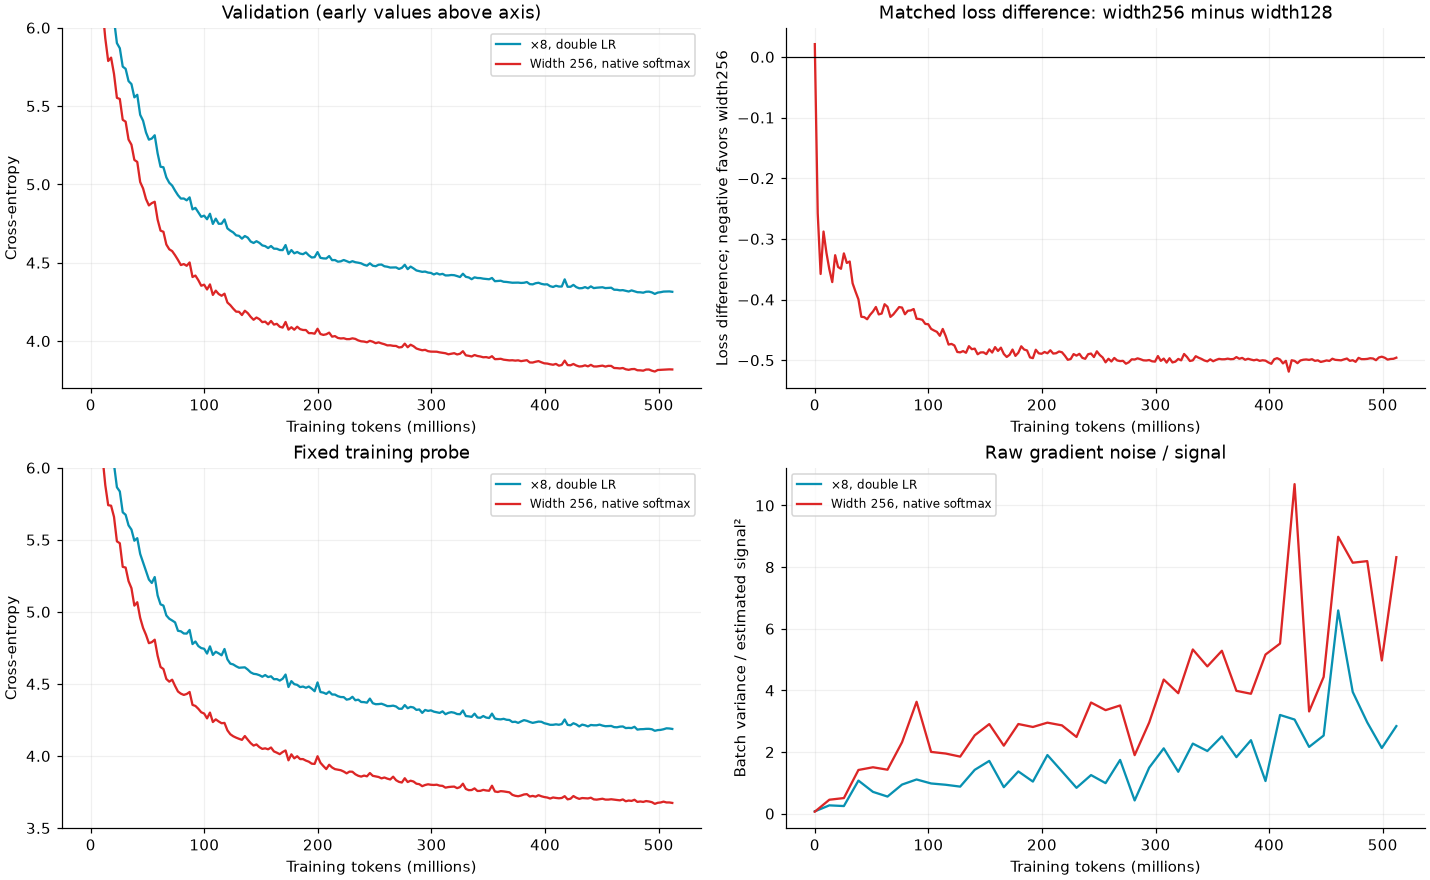

In [19]:
width_name = "gpt-mlx-basic-diagnostics-width256-01"
width_path = root / "artifacts/pretraining" / width_name
width_meta = json.loads((width_path / "metadata.json").read_text())
width_stats = [json.loads(line) for line in (width_path / "statistics.jsonl").read_text().splitlines()]
with (width_path / "metrics.csv").open() as file:
    width_metrics = [{key: float(value) if value else np.nan for key, value in row.items()}
                     for row in csv.DictReader(file)]
width = dict(name=width_name, label="Width 256, native softmax", color="#dc2626", path=width_path,
             metadata=width_meta, stats=width_stats, metrics=width_metrics)
assert width_meta["status"] == "completed"
for field in ("training_config", "data_config", "tokenizer_sha256", "token_cache", "statistics_config", "generation_config"):
    assert width_meta[field] == higher_meta[field], field
assert {k for k in width_meta["model_config"] if width_meta["model_config"][k] != higher_meta["model_config"][k]} == {"d_model", "stable_softmax"}
assert [r["step"] for r in width_metrics] == [r["step"] for r in higher_metrics]
assert width_metrics[-1]["tokens_processed"] == 512000000
assert sum(r["interval"]["updates"] for r in width_stats) == 25000

print(f"{'Run':<29} {'Params/M':>9} {'Final val':>10} {'Best val':>10} {'PPL':>8} {'Minutes':>9}")
for run in (higher, width):
    final = run["metrics"][-1]["val_loss"]
    print(f"{run['label']:<29} {run['metadata']['parameter_count']/1e6:9.3f} {final:10.5f} "
          f"{min(r['val_loss'] for r in run['metrics']):10.5f} {math.exp(final):8.2f} "
          f"{run['metrics'][-1]['elapsed_seconds']/60:9.2f}")
delta = values(width_metrics, "val_loss") - values(higher_metrics, "val_loss")
print(f"Wins after first update: {np.sum(delta[2:] < 0)}/{len(delta[2:])}")
print(f"Final perplexity reduction: {1 - np.exp(delta[-1]):.2%}")
for run in (higher, width):
    late = [r for r in run["stats"] if r["step"] > 20000 and "gradient_noise" in r]
    clip = sum(r["interval"]["updates"] * (r["interval"]["clipped_fraction"] or 0) for r in run["stats"]) / 25000
    print(run["label"], "clipped updates:", f"{clip:.2%}",
          "late median noise/signal:", np.median(values(late, "gradient_noise", "noise_to_signal")),
          "late median cosine:", np.median(values(late, "gradient_noise", "mean_pairwise_cosine")))
    print("Final fixed probes:", {k: v for k,v in run["stats"][-1]["probes"].items() if k != "activations"})

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for run in (higher, width):
    axes[0, 0].plot(token_x(run, run["metrics"]), values(run["metrics"], "val_loss"), color=run["color"], label=run["label"])
    axes[1, 0].plot(token_x(run, run["stats"]), values(run["stats"], "probes", "train_loss"), color=run["color"], label=run["label"])
    noise = [r for r in run["stats"] if "gradient_noise" in r]
    axes[1, 1].plot(token_x(run, noise), values(noise, "gradient_noise", "noise_to_signal"), color=run["color"], label=run["label"])
axes[0, 0].set_ylim(3.7, 6)
axes[1, 0].set_ylim(3.5, 6)
axes[0, 1].plot(token_x(width, width_metrics), delta, color=width["color"])
axes[0, 1].axhline(0, color="black", linewidth=0.8)
for ax, title, ylabel in zip(axes.ravel(),
    ["Validation (early values above axis)", "Matched loss difference: width256 minus width128", "Fixed training probe", "Raw gradient noise / signal"],
    ["Cross-entropy", "Loss difference; negative favors width256", "Cross-entropy", "Batch variance / estimated signal²"]):
    ax.set(title=title, xlabel="Training tokens (millions)", ylabel=ylabel)
for ax in (axes[0,0], axes[1,0], axes[1,1]):
    ax.legend(fontsize=8)
plt.show()


Final validation improves from **4.31443 to 3.81866** (perplexity **74.77 → 45.54**, a **39.1%** reduction). Best validation is **3.80553** at 496.64M tokens. Both fixed train and held-out probe losses improve, supporting a real capacity-related limitation in the earlier setup, with the softmax change as a confound.

The wider model is still learning near the end (validation 3.85413 at 409.6M tokens → 3.81866 at 512M), but sampled text remains grammatically and semantically unreliable. Higher raw gradient noise at the new weights accompanies better loss; it is not evidence of worse optimization. Runtime is 45.9 versus 72.7 minutes, with no controlled separation of softmax and hardware effects.
